# 0. Next-hour demand forecasting for NYC yellow taxis - sequential vs parallel

**CS4207 Advanced Programming - Coding Challenge - Group 11**

**Problem.** Forecast the number of NYC yellow-taxi pickups in the **next hour**, so taxi fleets can position
drivers before demand arrives. Built as a time-series regression on the TLC trip records
(January 2024 - September 2026, 33 monthly Parquet files, ~123 million trips), with the data pipeline and
the model search parallelised and benchmarked against a sequential version.

**How to run.** On Rockhill, from `~/cs4207-group11-demand`: `sbatch run_notebook.slurm`
(8 CPUs, 32 GB, CPU only). The timing benchmarks with warm-up and 3 repeats run separately with
`sbatch run_benchmark.slurm` (`scripts/benchmark.py`); section 9 loads their output.
**Expected run time:** about 10-15 minutes on 8 cores (the actual time is printed in section 12).

**Code layout.** Worker functions live in `src/demand/` (not in the notebook) because
`ProcessPoolExecutor` workers must be able to *import* the functions they run - the same reason the
week 9 lab used a separate `workers.py`. The key functions are shown with `inspect.getsource` where they matter.

In [1]:
import time
NOTEBOOK_START = time.perf_counter()

import sys, os
sys.path.insert(0, "src")

from demand.parallel import SINGLE_THREAD_ENV
os.environ.update(SINGLE_THREAD_ENV)   # single-threaded maths everywhere (fair + deterministic timings)

import inspect, json, platform, subprocess
from pathlib import Path

import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
import sklearn, matplotlib
from IPython.display import Image, display

from demand import cleaning, config, features, io, models, nondeterminism, parallel, plotting

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 20)
config.OUTPUT_DIR.mkdir(exist_ok=True)
config.FIGURE_DIR.mkdir(exist_ok=True)
RESULTS = {}   # every number that the poster uses is collected here -> outputs/results.json

# 1. Configuration and environment

Every setting (paths, months, thresholds, split dates, seeds, worker counts, hyperparameter grid) lives in
**one place**: `src/demand/config.py`. Below we print it together with the software versions and the hardware
this run used, so the results can be reproduced.

In [2]:
N_WORKERS = min(8, config.available_cpus())
def sh(cmd):
    return subprocess.run(cmd, shell=True, capture_output=True, text=True).stdout.strip()

env = {
    "python": platform.python_version(), "pandas": pd.__version__, "numpy": np.__version__,
    "pyarrow": pa.__version__, "scikit-learn": sklearn.__version__, "matplotlib": matplotlib.__version__,
    "hostname": platform.node(), "cpu_model": sh("lscpu | grep 'Model name' | cut -d: -f2 | xargs"),
    "cpus_allocated": config.available_cpus(), "gpu": "none used (CPU-only task)",
    "slurm_job_id": os.environ.get("SLURM_JOB_ID"),
}
settings = {
    "seed": config.SEED, "workers_used_in_notebook": N_WORKERS, "worker_counts_benchmarked": config.WORKER_COUNTS,
    "thresholds": {"min_duration_min": config.MIN_DURATION_MIN, "max_duration_min": config.MAX_DURATION_MIN,
                   "max_distance_miles": config.MAX_DISTANCE_MILES, "min_fare_exclusive": config.MIN_FARE},
    "split": {"train_end": config.TRAIN_END, "val": [config.VAL_START, config.VAL_END],
              "test": [config.TEST_START, config.TEST_END], "cv_folds": config.N_CV_FOLDS,
              "cv_fold_hours": config.CV_TEST_SIZE},
    "data_dir": str(config.DATA_DIR),
}
RESULTS["environment"], RESULTS["settings"] = env, settings
print(json.dumps(env, indent=1)); print(json.dumps(settings, indent=1))

{
 "python": "3.12.3",
 "pandas": "3.1.1",
 "numpy": "2.5.5",
 "pyarrow": "26.0.1",
 "scikit-learn": "1.9.1",
 "matplotlib": "3.11.2",
 "hostname": "rockhill",
 "cpu_model": "AMD EPYC 9124 16-Core Processor",
 "cpus_allocated": 8,
 "gpu": "none used (CPU-only task)",
 "slurm_job_id": "2023"
}
{
 "seed": 42,
 "workers_used_in_notebook": 8,
 "worker_counts_benchmarked": [
  1,
  2,
  4,
  8
 ],
 "thresholds": {
  "min_duration_min": 1.0,
  "max_duration_min": 180.0,
  "max_distance_miles": 100.0,
  "min_fare_exclusive": 0.0
 },
 "split": {
  "train_end": "2026-07-31 23:00",
  "val": [
   "2026-08-01 00:00",
   "2026-08-31 23:00"
  ],
  "test": [
   "2026-09-01 00:00",
   "2026-09-30 23:00"
  ],
  "cv_folds": 4,
  "cv_fold_hours": 672
 },
 "data_dir": "/home/cs4207/data"
}


# 2. Data inventory (footer inspection)

Before reading any data we inspect each Parquet file's **footer** (metadata). It holds the row count, the
row groups and the schema, so we learn the size of every shard without decoding a single value.
Look for: similar row counts per month (important for load balance in section 4) and schema drift
(columns added over time).

In [3]:
FILES = config.month_files()
inventory = io.file_inventory(FILES)
inventory.to_csv(config.OUTPUT_DIR / "file_inventory.csv", index=False)
print(f"{len(FILES)} files, {inventory['rows'].sum():,} rows, {inventory['size_mb'].sum():,.0f} MB on disk")
print(f"rows per month: min {inventory['rows'].min():,}  max {inventory['rows'].max():,}  "
      f"(largest/smallest = {inventory['rows'].max() / inventory['rows'].min():.2f})")
display(inventory.head(3)); display(inventory.tail(3))
print("Columns that are not in every file:")
display(io.schema_differences(FILES))
RESULTS["data"] = {
    "months": [inventory["month"].iloc[0], inventory["month"].iloc[-1]], "n_files": len(FILES),
    "raw_rows": int(inventory["rows"].sum()), "size_mb": float(inventory["size_mb"].sum()),
    "rows_per_month_min": int(inventory["rows"].min()), "rows_per_month_max": int(inventory["rows"].max()),
    "files": f"yellow_tripdata_{inventory['month'].iloc[0]}.parquet ... yellow_tripdata_{inventory['month'].iloc[-1]}.parquet",
    "source": "NYC TLC Trip Record Data (yellow taxi), provided at /home/cs4207/data on Rockhill",
}

33 files, 123,471,721 rows, 2,102 MB on disk
rows per month: min 2,964,624  max 4,591,845  (largest/smallest = 1.55)


,month,file,rows,row_groups,columns,size_mb
0,2024-01,yellow_tripdata_2024-01.parquet,2964624,3,19,50.0
1,2024-02,yellow_tripdata_2024-02.parquet,3007526,3,19,50.3
2,2024-03,yellow_tripdata_2024-03.parquet,3582628,4,19,60.1


,month,file,rows,row_groups,columns,size_mb
30,2026-07,yellow_tripdata_2026-07.parquet,3530109,4,21,61.7
31,2026-08,yellow_tripdata_2026-08.parquet,3336716,4,21,59.0
32,2026-09,yellow_tripdata_2026-09.parquet,3876044,4,21,67.4


Columns that are not in every file:


,column,first_month,n_months
0,cbd_congestion_fee,2025-01,21
1,request_source,2026-06,4


# 3. Data cleaning and preprocessing

**Efficient loading.** We read only the 10 columns we need (`columns=[...]`, *column pruning*): the
tip, toll and surcharge columns are never decoded. Below, one month (April 2026) is inspected in detail.

**What is wrong with the raw data** (numbers printed below): pickups dated outside the file's month
(even 2001), trips of 0 seconds or almost 7 days, distances of 0 or hundreds of thousands of miles,
negative fares (refunds). About a fifth of rows have nulls in `RatecodeID`, `passenger_count` and the
surcharge columns - we check whether these are the **Flex Fare** trips.

In [4]:
MONTH = "2026-04"
apr = io.read_month(config.DATA_DIR / f"yellow_tripdata_{MONTH}.parquet")
print(f"{MONTH}: {len(apr):,} rows, {apr.shape[1]} columns read, "
      f"{apr.memory_usage(deep=True).sum() / 1e6:,.0f} MB in memory")
dur_min = (apr["tpep_dropoff_datetime"] - apr["tpep_pickup_datetime"]).dt.total_seconds() / 60
display(pd.DataFrame({
    "min": [apr["tpep_pickup_datetime"].min(), dur_min.min(), apr["trip_distance"].min(), apr["fare_amount"].min()],
    "max": [apr["tpep_pickup_datetime"].max(), dur_min.max(), apr["trip_distance"].max(), apr["fare_amount"].max()],
}, index=["pickup time", "duration (min)", "distance (miles)", "fare ($)"]))
nulls = io.footer_null_counts(config.DATA_DIR / f"yellow_tripdata_{MONTH}.parquet")
print("Null counts of ALL columns, from footer statistics (no data read):")
print(nulls[nulls > 0].to_string())

2026-04: 3,831,240 rows, 10 columns read, 261 MB in memory


,min,max
pickup time,2001-01-01 09:23:58,2026-05-01 00:01:28
duration (min),0.0,9983.933333
distance (miles),0.0,281576.08
fare ($),-1274.9,1442.2


Null counts of ALL columns, from footer statistics (no data read):
passenger_count         799786
RatecodeID              799786
store_and_fwd_flag      799786
congestion_surcharge    799786
Airport_fee             799786


**Where is "Flex Fare"?** The 2026 files have no column called Flex Fare. The TLC data dictionary defines
`payment_type = 0` as a *Flex Fare trip* and `RatecodeID = 99` as *unknown*. The cross-tab shows that
**every** row with a null `RatecodeID` has `payment_type = 0` - the nulls *are* the Flex Fare trips.

In [5]:
flex = pd.crosstab(apr["payment_type"], apr["RatecodeID"].isna().map({True: "RatecodeID null", False: "RatecodeID set"}))
display(flex)
flex_rows = int((apr["payment_type"] == config.FLEX_FARE_PAYMENT_TYPE).sum())
flex_fare_pos = float((apr.loc[apr["payment_type"] == 0, "fare_amount"] > 0).mean() * 100)
print(f"Flex Fare rows in {MONTH}: {flex_rows:,} ({100 * flex_rows / len(apr):.1f}%); "
      f"{flex_fare_pos:.1f}% of them have a positive fare and normal trip times.")

RatecodeID,RatecodeID null,RatecodeID set
payment_type,,
0,799786,0
1,0,2635749
2,0,360995
3,0,11792
4,0,22918


Flex Fare rows in 2026-04: 799,786 (20.9%); 99.8% of them have a positive fare and normal trip times.


**Decision on Flex Fare / missing rate codes: keep them.** Our target is *pickup demand*. A Flex Fare trip is
a real passenger pickup; only its fare type is unknown. Dropping them would remove ~20-30% of real demand and
create a fake drop in mid-2025 when Flex Fare became common. Instead `RatecodeID` becomes a category with an
explicit `unknown` level (null and 99). Any Flex Fare rows that are junk (zero distance, zero fare) are removed
anyway by the generic rules below.

**The cleaning rules**, applied in this order, each counting the rows it removes (thresholds in `config.py`):

| # | Rule | Why |
|---|---|---|
| 1 | pickup outside the file's month | spill-over from Dec/next month, faulty clocks (2001) |
| 2 | duration < 1 min, > 3 h, or dropoff before pickup | meter started by mistake / left running |
| 3 | distance <= 0 or > 100 miles | zero-distance trips and meter errors (max seen 281,576 miles) |
| 4 | fare <= 0 | refunds, voids, disputes |
| 5 | exact duplicate rows | the same trip recorded twice |

Then zone and rate codes are encoded as `category`, and trips are counted per clock hour.

In [6]:
print(inspect.getsource(cleaning.apply_rules))

def apply_rules(df: pd.DataFrame, month: str) -> tuple[pd.DataFrame, dict]:
    """Apply the cleaning rules in a fixed order, counting how many rows each rule removes."""
    removed: dict[str, int] = {}
    start = pd.Timestamp(f"{month}-01")
    end = start + pd.offsets.MonthBegin(1)

    def drop(mask: pd.Series, rule: str) -> pd.DataFrame:
        removed[rule] = int(mask.sum())
        return df.loc[~mask]

    # 1. Spill-over from the previous/next month and bad clocks (e.g. a pickup dated 2001).
    pick = df["tpep_pickup_datetime"]
    df = drop((pick < start) | (pick >= end), "pickup_outside_month")

    # 2. Dropoff before pickup, under 1 minute or over 3 hours.
    minutes = (df["tpep_dropoff_datetime"] - df["tpep_pickup_datetime"]).dt.total_seconds() / 60
    df = drop((minutes < config.MIN_DURATION_MIN) | (minutes > config.MAX_DURATION_MIN),
              "duration_out_of_range")

    # 3. Zero distance or meter errors (hundreds of thousands of miles).
    dist = df["trip_

In [7]:
y_apr, stats_apr = cleaning.clean_month(config.DATA_DIR / f"yellow_tripdata_{MONTH}.parquet")
print(json.dumps(stats_apr, indent=1))
print("Mean pickups/hour in", MONTH, round(y_apr.mean(), 1))

{
 "month": "2026-04",
 "raw_rows": 3831240,
 "removed_pickup_outside_month": 12,
 "removed_duration_out_of_range": 89425,
 "removed_distance_out_of_range": 66135,
 "removed_fare_not_positive": 14040,
 "removed_duplicate_rows": 0,
 "kept_rows": 3661628,
 "flex_fare_kept": 738705,
 "ratecode_unknown_kept": 884017,
 "missing_hours": 0,
 "fare_sum": 76987896.54
}
Mean pickups/hour in 2026-04 5085.6


**Missing hours.** After counting per hour we re-index to *every* hour of the month and fill gaps with 0,
because an hour without a recorded pickup is zero demand, not unknown demand. TLC timestamps are naive
local time, so the hour 02:00-02:59 on the US spring-forward day does not exist on the clock: it is the only
kind of "missing" hour we find (one per March, shown in section 4). We leave it as 0 and note it rather than
invent a value; with ~24,000 hourly rows its effect is negligible.

**Memory - `iter_batches`.** Reading a whole month with pruned columns peaks at about 2 GB per process. If
months were much larger we would stream them with `iter_batches` (500,000 rows at a time) - rules 1-4 are
row-local, so per-batch hourly counts can simply be added. We check below that the streamed result equals the
whole-month result.

In [8]:
t0 = time.perf_counter()
y_stream = cleaning.hourly_counts_streaming(config.DATA_DIR / f"yellow_tripdata_{MONTH}.parquet")
print(f"iter_batches result equals whole-month result: {y_stream.equals(y_apr)}  ({time.perf_counter() - t0:.1f} s)")
del apr

iter_batches result equals whole-month result: True  (1.5 s)


# 4. Data parallelism: sharded cleaning and aggregation

**Sharding scheme: one shard = one month file.**
- It matches how the data is stored, so a worker never reads across files.
- Each shard keeps its own time order and the shards cover non-overlapping hours, so combining is a
  simple ordered concatenation (map -> reduce).
- Shards are similar in size (2.96 M - 4.59 M rows, see section 2), so the work is fairly balanced.

The **same function** `clean_month` runs on every shard. `run_sequential` is a plain loop; `run_parallel`
uses `ProcessPoolExecutor.map`, which returns results in **input order**. `combine_months` additionally sorts
by month (a fixed reduction order) before concatenating and summing the statistics.

In [9]:
print(inspect.getsource(parallel.run_parallel)); print(inspect.getsource(cleaning.combine_months))

def run_parallel(func: Callable, items: Iterable, workers: int) -> list:
    """Same work spread over `workers` processes.

    `executor.map` returns results in INPUT order, not completion order, so the combined
    result is deterministic (see the non-determinism section for what happens otherwise).
    """
    items = list(items)
    with ProcessPoolExecutor(max_workers=workers, initializer=pin_single_thread) as ex:
        return list(ex.map(func, items, chunksize=1))

def combine_months(results: list[tuple[pd.Series, dict]]) -> tuple[pd.Series, pd.DataFrame]:
    """Reduce step: join per-month series in month order and stack the per-month stats.

    Months never overlap in time, so joining is a plain concatenation - no partial counts
    for the same hour need adding together.
    """
    results = sorted(results, key=lambda r: r[1]["month"])   # fixed order, whatever arrived first
    series = pd.concat([s for s, _ in results])
    stats = pd.DataFrame([st for _, st in results])

In [10]:
t0 = time.perf_counter()
seq_results = parallel.run_sequential(cleaning.clean_month, FILES)
t_clean_seq = time.perf_counter() - t0
t0 = time.perf_counter()
par_results = parallel.run_parallel(cleaning.clean_month, FILES, N_WORKERS)
t_clean_par = time.perf_counter() - t0

y_seq, stats_seq = cleaning.combine_months(seq_results)
y, stats = cleaning.combine_months(par_results)
clean_equal = bool(y.equals(y_seq) and stats.equals(stats_seq))
print(f"sequential: {t_clean_seq:.1f} s   parallel ({N_WORKERS} workers): {t_clean_par:.1f} s   "
      f"speedup {t_clean_seq / t_clean_par:.2f}x")
print("Parallel result identical to sequential (series AND cleaning stats):", clean_equal)
assert clean_equal

sequential: 127.4 s   parallel (8 workers): 20.2 s   speedup 6.32x
Parallel result identical to sequential (series AND cleaning stats): True


**Cleaning table over all 33 months** (rule -> rows removed). The per-month version is saved to
`outputs/cleaning_by_month.csv`.

In [11]:
ctable = cleaning.cleaning_table(stats)
ctable.to_csv(config.OUTPUT_DIR / "cleaning_table.csv", index=False)
stats.to_csv(config.OUTPUT_DIR / "cleaning_by_month.csv")
display(ctable)
print("Missing (zero-pickup) hours filled with 0:", int(stats["missing_hours"].sum()),
      "->", list(y[y == 0].index.astype(str)))
print(f"Flex Fare trips kept: {int(stats['flex_fare_kept'].sum()):,}   "
      f"rate code 'unknown' kept: {int(stats['ratecode_unknown_kept'].sum()):,}")
print(f"hourly observations: {len(y):,}   mean pickups/hour: {y.mean():,.1f}")

,rule,rows,pct_of_raw
0,raw rows,123471721,100.000
1,pickup_outside_month,802,0.001
2,duration_out_of_range,2413007,1.954
3,distance_out_of_range,2306367,1.868
4,fare_not_positive,3393484,2.748
5,duplicate_rows,2,0.000
6,kept rows,115358059,93.429


Missing (zero-pickup) hours filled with 0: 3 -> ['2024-03-10 02:00:00', '2025-03-09 02:00:00', '2026-03-08 02:00:00']
Flex Fare trips kept: 20,632,993   rate code 'unknown' kept: 22,709,321
hourly observations: 24,096   mean pickups/hour: 4,787.4


**Balance and memory per shard.** We time every shard and record the peak memory of the worker that cleaned
it. With 33 shards on 8 workers there are ceil(33/8) = 5 "rounds": the 8 workers finish 32 shards in 4 rounds,
then one worker cleans the 33rd while 7 sit idle - a source of **load imbalance**. Shard *sizes* also differ by
up to 1.55x.

In [12]:
profile = pd.DataFrame(parallel.run_parallel(cleaning.clean_month_profiled, FILES, N_WORKERS))
profile = profile.merge(inventory[["month", "rows"]], on="month")
profile.to_csv(config.OUTPUT_DIR / "shard_profile.csv", index=False)
print(f"per-shard seconds: min {profile['seconds'].min():.1f}  mean {profile['seconds'].mean():.1f}  "
      f"max {profile['seconds'].max():.1f};  peak RSS per worker: max {profile['peak_rss_mb'].max():,.0f} MB")
print(f"correlation of shard time with shard rows: {profile['seconds'].corr(profile['rows']):.2f}")

per-shard seconds: min 3.1  mean 4.5  max 5.5;  peak RSS per worker: max 2,368 MB
correlation of shard time with shard rows: 0.76


,window,day_type,mean_pickups_per_hour
0,morning_peak 07:00-09:59,weekday,4934.2
1,morning_peak 07:00-09:59,weekend,2432.2
2,evening_peak 16:00-19:59,weekday,7390.0
3,evening_peak 16:00-19:59,weekend,6987.8
4,all hours,all,4787.4


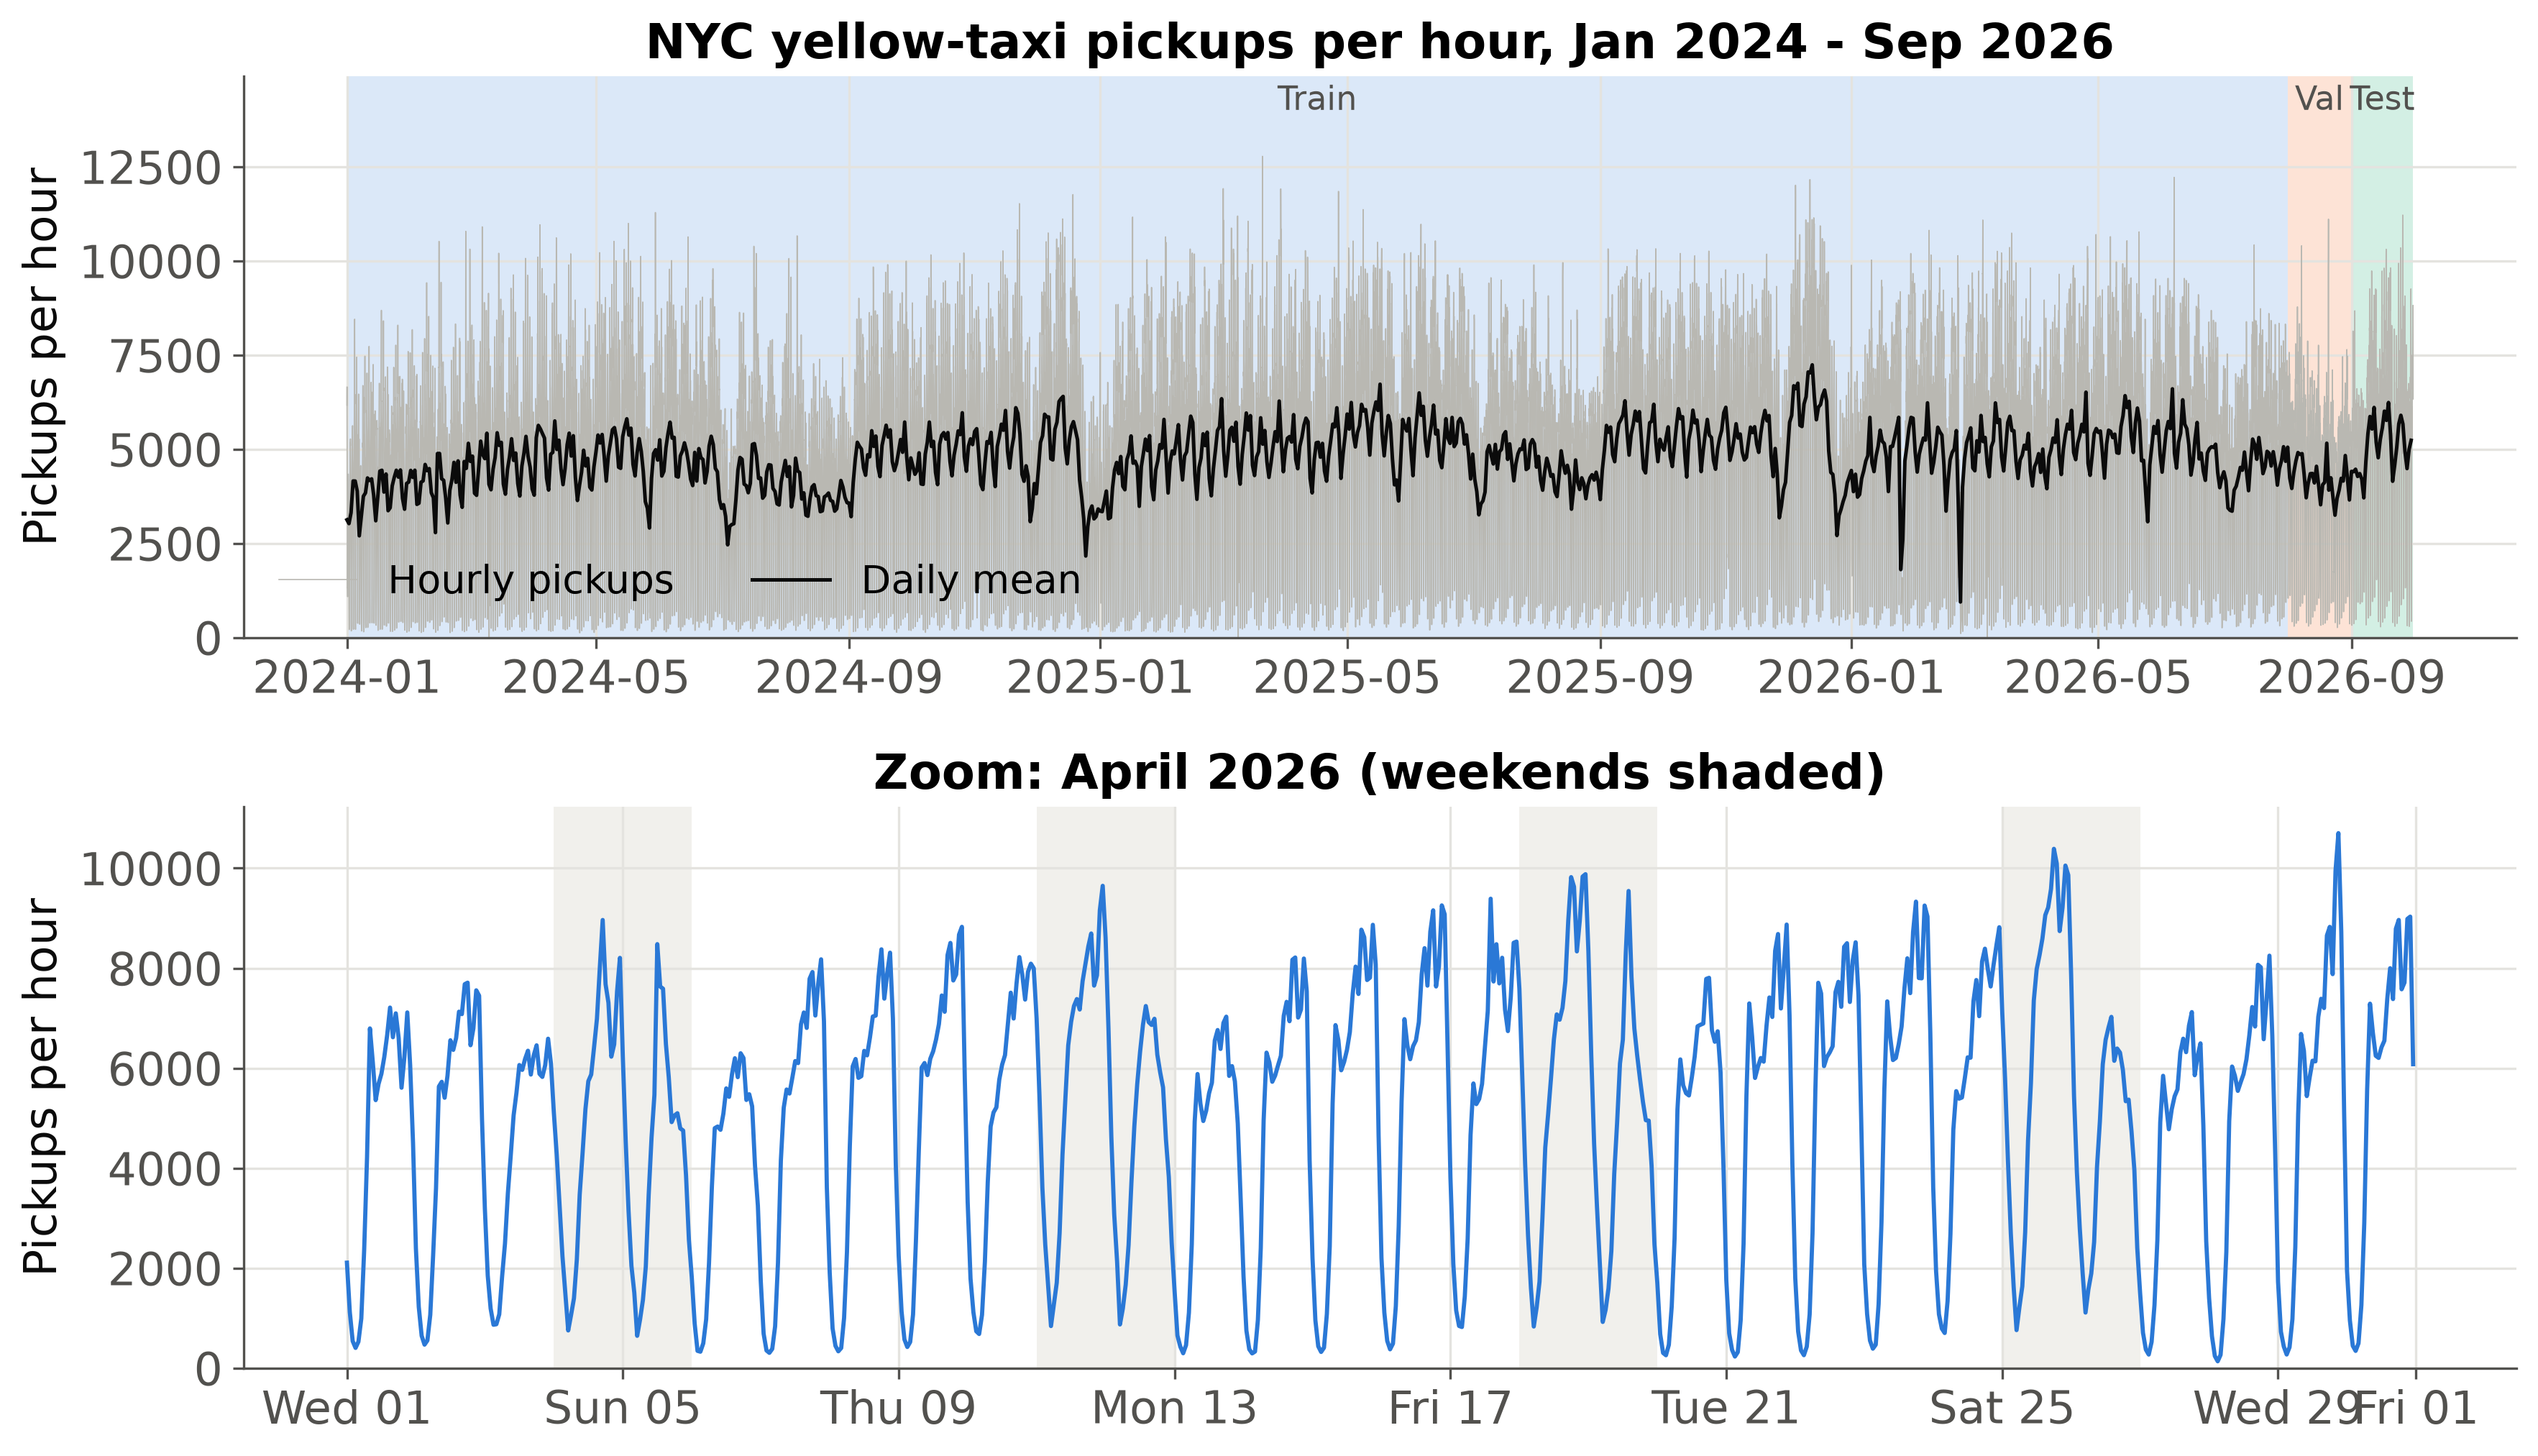

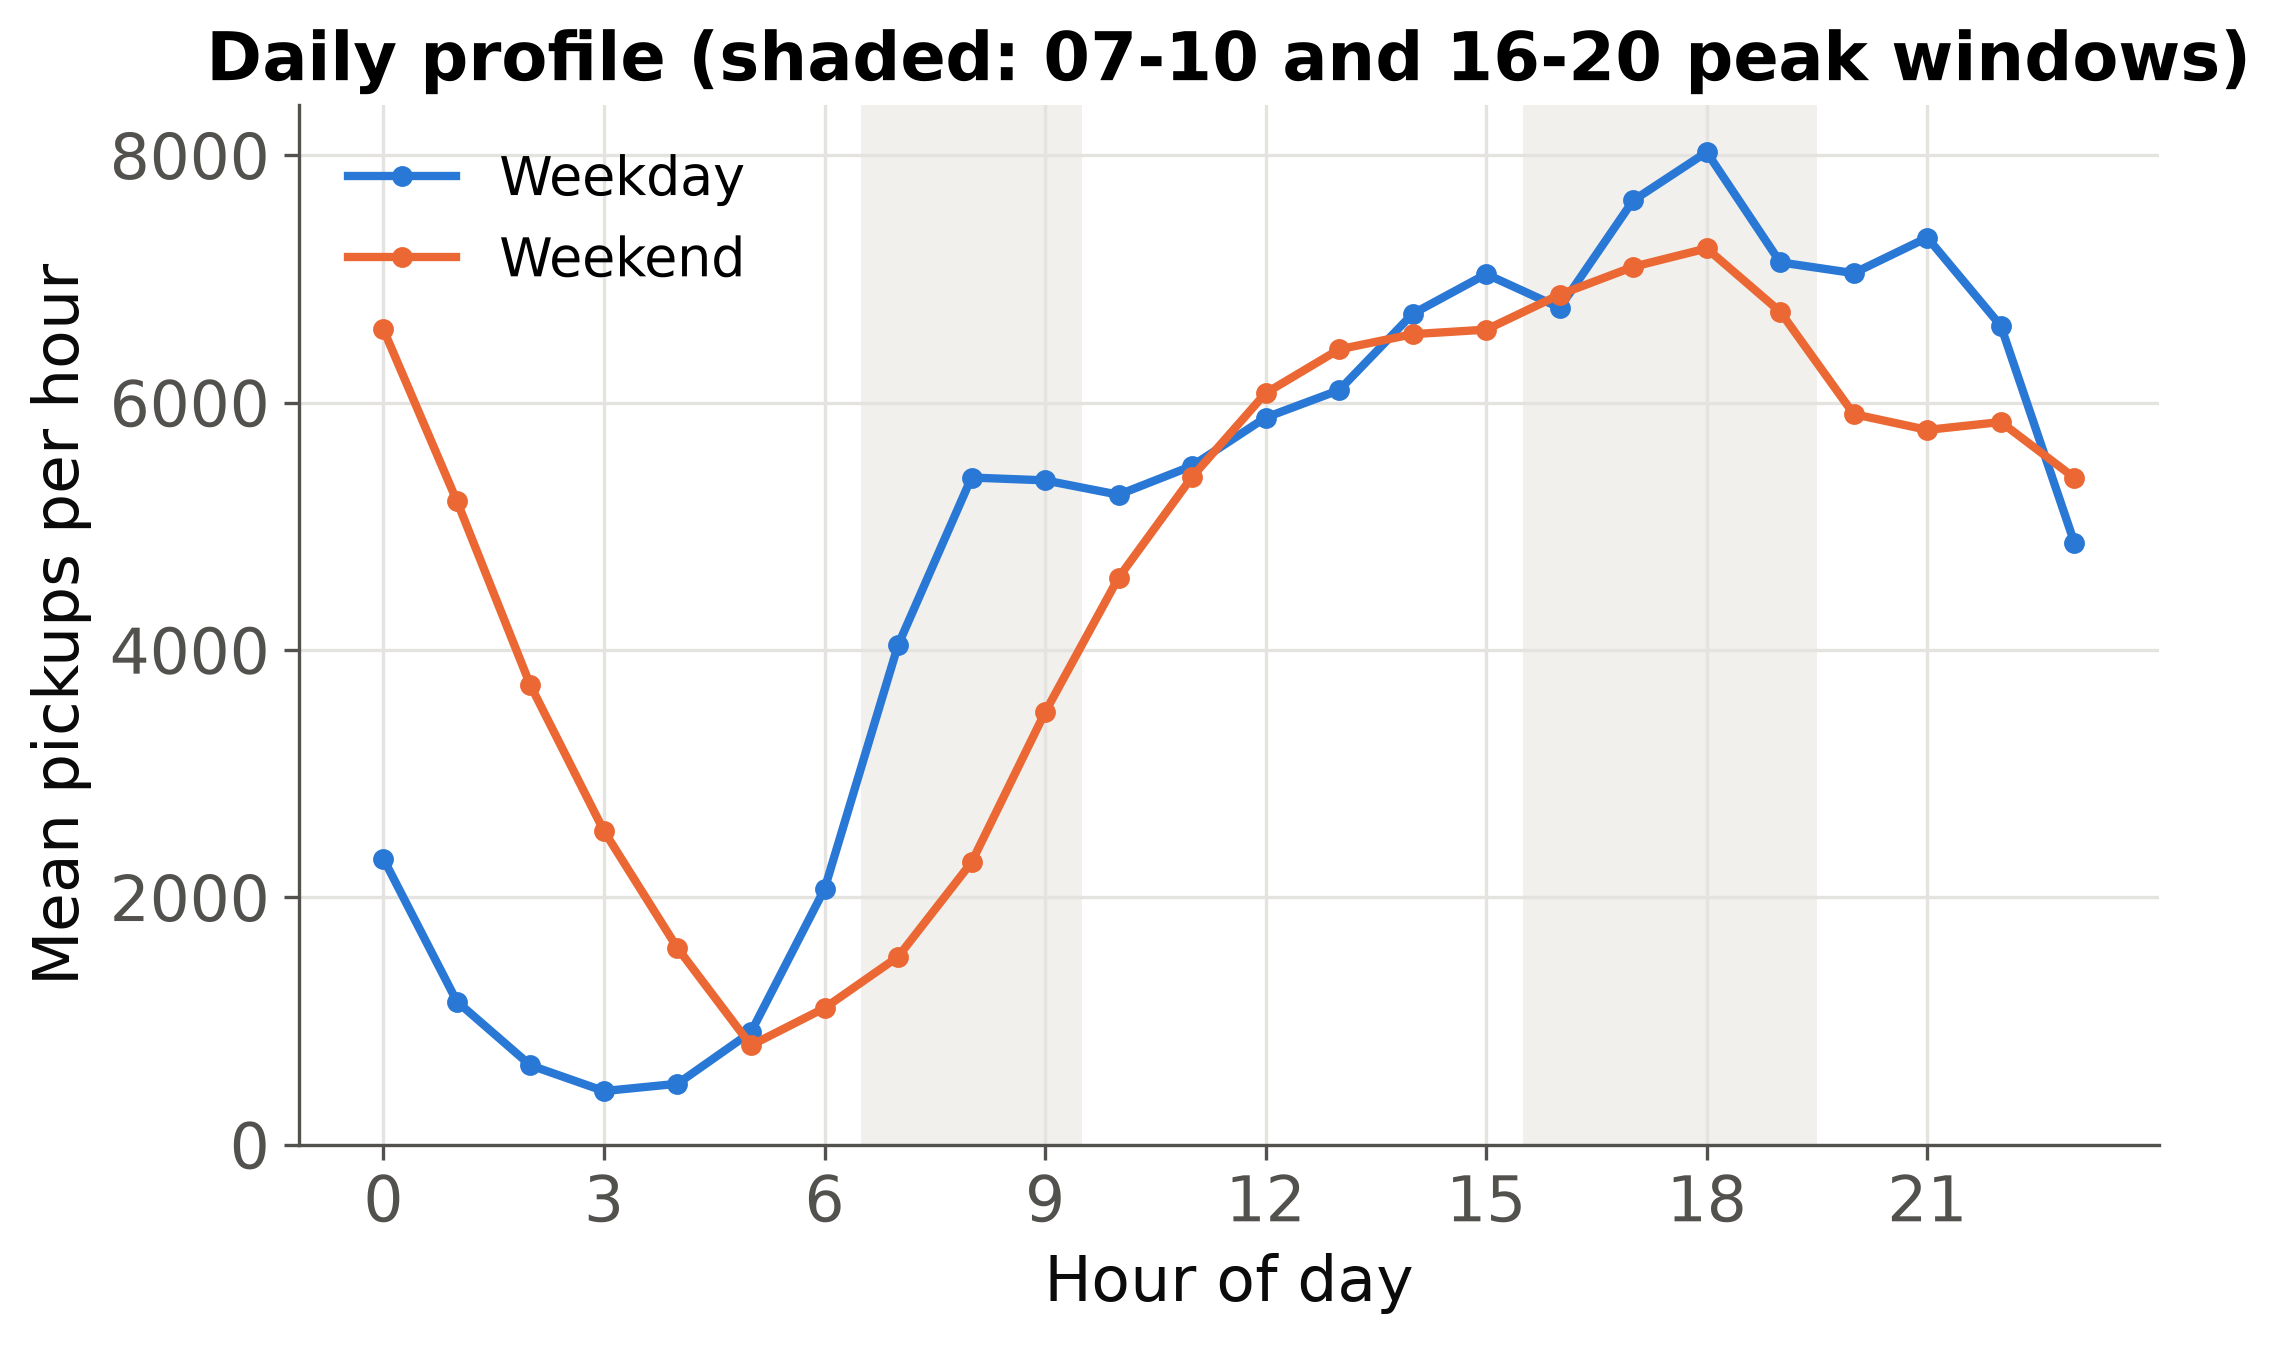

In [13]:
peaks = cleaning.peak_profile(y)
peaks.to_csv(config.OUTPUT_DIR / "peak_profile.csv", index=False)
display(peaks)
display(Image(str(plotting.hourly_series(y))))
display(Image(str(plotting.daily_weekly_profile(y))))

RESULTS["cleaning"] = {
    "raw_rows": int(stats["raw_rows"].sum()), "kept_rows": int(stats["kept_rows"].sum()),
    "kept_pct": float(100 * stats["kept_rows"].sum() / stats["raw_rows"].sum()),
    "removed": {r: int(stats[f"removed_{r}"].sum()) for r in cleaning.RULES},
    "flex_fare_kept": int(stats["flex_fare_kept"].sum()),
    "ratecode_unknown_kept": int(stats["ratecode_unknown_kept"].sum()),
    "missing_hours_filled": int(stats["missing_hours"].sum()),
    "hourly_observations": int(len(y)), "mean_pickups_per_hour": float(y.mean()),
    "april_2026_check": {k: v for k, v in stats_apr.items() if k != "fare_sum"},
    "flex_fare_share_apr_2026_pct": 100 * flex_rows / stats_apr["raw_rows"],
    "peak_profile": peaks.to_dict(orient="records"),
}
RESULTS["data_parallel"] = {
    "shards": len(FILES), "workers": N_WORKERS, "identical_to_sequential": clean_equal,
    "shard_seconds_min": float(profile["seconds"].min()), "shard_seconds_max": float(profile["seconds"].max()),
    "peak_rss_mb_max": float(profile["peak_rss_mb"].max()),
    "iter_batches_equal": bool(y_stream.equals(y_apr)),
}

# 5. Time-based split and leakage controls

A time series must be split **by time**, never at random: a random split would let the model train on hours
that come *after* the hours it is tested on.

- **History:** the first 168 hours (+1) only provide the 168-hour lag; rows with missing features are dropped.
- **Train:** up to 31 Jul 2026. The hyperparameter search uses 4 expanding-window `TimeSeriesSplit` folds
  *inside* train, each validating on the 4 weeks after its training block.
- **Validation:** Aug 2026 - choose between the best Ridge and the best gradient-boosting model.
- **Test:** Sep 2026 - scored **once**, at the end, by a model retrained on train + validation.

**Leakage controls:** every feature for hour *t* uses only hours <= *t-1* (lags `shift(k>=1)`, rolling windows on
`y.shift(1)` - shift first, then roll); no fares, tips or distances from the predicted hour; the scaler sits in a
`Pipeline`, so it is fitted on each fold's training rows only; the test month is never used for any choice.

train: 2024-01-08 00:00:00 -> 2026-07-31 23:00:00  (22,464 hours)
val  : 2026-08-01 00:00:00 -> 2026-08-31 23:00:00  (744 hours)
test : 2026-09-01 00:00:00 -> 2026-09-30 23:00:00  (720 hours)
Leakage checks passed: lag_1 = previous hour, rolling windows end at t-1, train < val < test
CV fold 0: train 2024-01-08 -> 2026-04-10, validate 2026-04-11 -> 2026-05-08
CV fold 1: train 2024-01-08 -> 2026-05-08, validate 2026-05-09 -> 2026-06-05
CV fold 2: train 2024-01-08 -> 2026-06-05, validate 2026-06-06 -> 2026-07-03
CV fold 3: train 2024-01-08 -> 2026-07-03, validate 2026-07-04 -> 2026-07-31


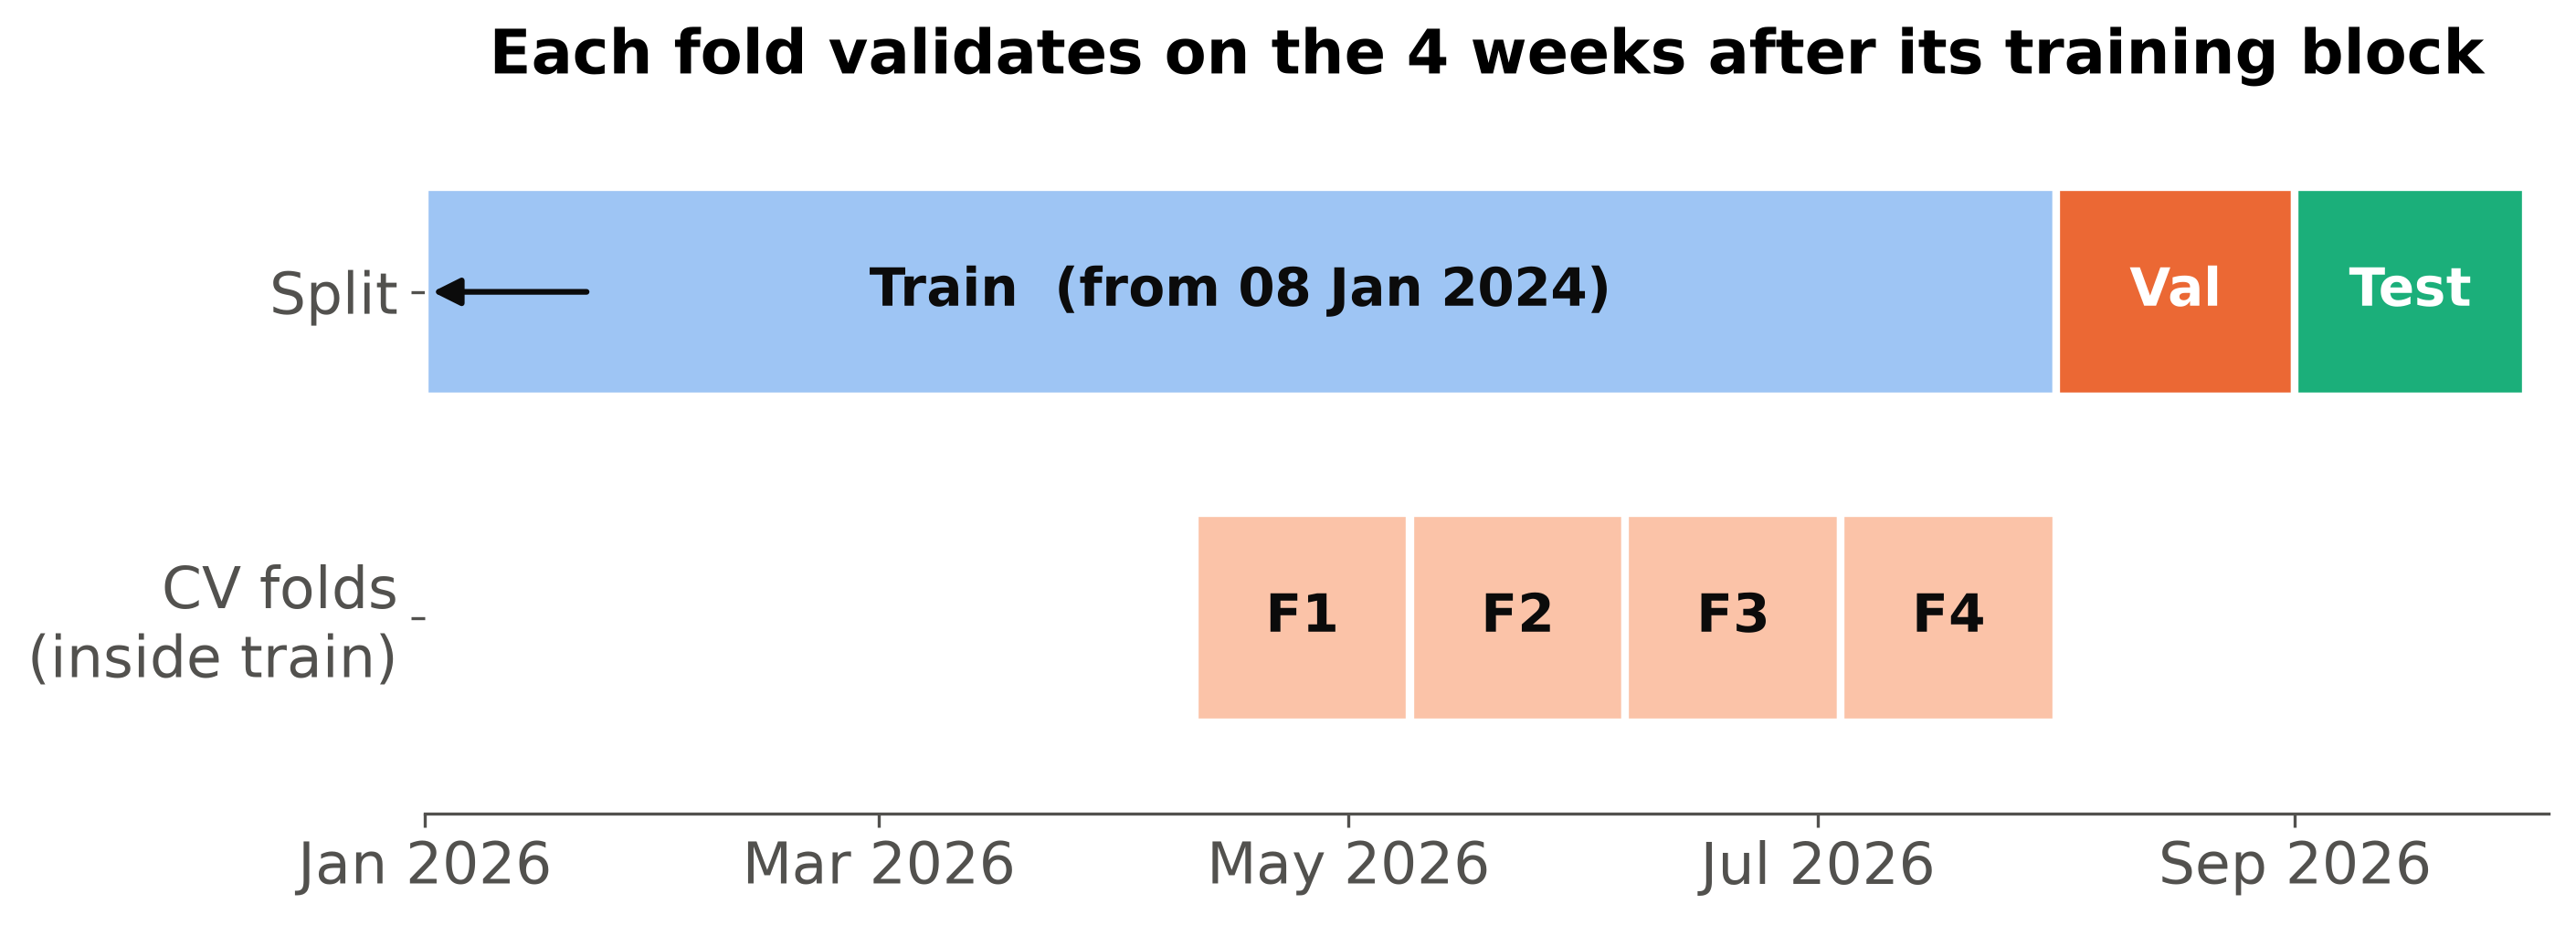

In [14]:
blocks = parallel.run_sequential(features.run_feature_task, features.feature_tasks(y))
X = features.join_feature_blocks(blocks)
table = features.model_table(X, y)
parts = features.split(table)
for name, part in parts.items():
    print(f"{name:5s}: {part.index[0]} -> {part.index[-1]}  ({len(part):,} hours)")

# Automatic leakage checks
assert (X["lag_1"].iloc[1:].to_numpy() == y.iloc[:-1].to_numpy()).all(), "lag_1 must equal the previous hour"
assert np.allclose(X["roll_mean_24"].iloc[24:], y.shift(1).rolling(24).mean().iloc[24:]), "rolling must use past only"
assert parts["train"].index.max() < parts["val"].index.min() < parts["test"].index.min()
print("Leakage checks passed: lag_1 = previous hour, rolling windows end at t-1, train < val < test")

Xtr, ytr = parts["train"][config.FEATURE_COLUMNS], parts["train"]["y"]
folds = models.cv_folds(len(Xtr))
fold_ranges = [(Xtr.index[va[0]], Xtr.index[va[-1]]) for _, va in folds]
for i, (s, e) in enumerate(fold_ranges):
    print(f"CV fold {i}: train {Xtr.index[0]:%Y-%m-%d} -> {Xtr.index[folds[i][0][-1]]:%Y-%m-%d}, validate {s:%Y-%m-%d} -> {e:%Y-%m-%d}")
display(Image(str(plotting.time_split(y.index, table.index[0], fold_ranges))))

RESULTS["split"] = {name: {"start": str(p.index[0]), "end": str(p.index[-1]), "hours": len(p)} for name, p in parts.items()}
RESULTS["split"]["history_hours_dropped"] = int(len(y) - len(table))
RESULTS["split"]["cv_folds"] = [{"start": str(s), "end": str(e)} for s, e in fold_ranges]

# 6. Task parallelism 1: feature extraction

The three feature groups are **independent tasks**: each reads only the hourly series and returns its own
block of columns; none needs another's output. We run them as separate processes and rejoin them in a **fixed
column order** (`config.FEATURE_TASKS` / `FEATURE_COLUMNS`), so the table is identical whichever task finishes
first.

What to expect: the series has only ~24,000 rows, so each task takes milliseconds while starting a process and
sending the series to it takes far longer. Parallel will be **slower** - an honest example of overheads
dominating (Amdahl's law with a large serial fraction).

In [15]:
print(inspect.getsource(features.rolling_features))
feat_seq_times, feat_seq = parallel.time_runs(
    lambda: parallel.run_sequential(features.run_feature_task, features.feature_tasks(y)), repeats=3)
feat_par_times, feat_par = parallel.time_runs(
    lambda: parallel.run_parallel(features.run_feature_task, features.feature_tasks(y), 3), repeats=3)
feat_equal = bool(features.join_feature_blocks(feat_par).equals(features.join_feature_blocks(feat_seq)))
print(f"sequential: {np.mean(feat_seq_times) * 1000:.0f} ms   parallel (3 workers): {np.mean(feat_par_times) * 1000:.0f} ms")
print("Parallel feature table identical to sequential:", feat_equal)
assert feat_equal
print("Columns in fixed order:", list(X.columns))
RESULTS["features"] = {"n_features": len(config.FEATURE_COLUMNS), "columns": config.FEATURE_COLUMNS,
                       "identical_to_sequential": feat_equal}

def rolling_features(y: pd.Series) -> pd.DataFrame:
    """Mean / std / max of the last 3, 24 and 168 hours, ending at t-1."""
    past = y.shift(1)
    cols = {}
    for w in config.ROLL_WINDOWS:
        roll = past.rolling(w)
        for s in config.ROLL_STATS:
            cols[f"roll_{s}_{w}"] = getattr(roll, s)()
    return pd.DataFrame(cols, index=y.index)



sequential: 17 ms   parallel (3 workers): 123 ms
Parallel feature table identical to sequential: True
Columns in fixed order: ['lag_1', 'lag_2', 'lag_3', 'lag_24', 'lag_48', 'lag_168', 'roll_mean_3', 'roll_std_3', 'roll_max_3', 'roll_mean_24', 'roll_std_24', 'roll_max_24', 'roll_mean_168', 'roll_std_168', 'roll_max_168', 'hour_sin', 'hour_cos', 'dow_sin', 'dow_cos', 'is_weekend', 'month', 'is_holiday']


# 7. Task parallelism 2: hyperparameter search

**Baselines first** (no model): *same hour yesterday* (`lag_24`) and *same hour last week* (`lag_168`). In the
course's worked example, "same hour last week" beat a tuned Ridge model, so we must compare honestly.

**Models:** Ridge (linear; inside `Pipeline(StandardScaler, Ridge)`) and `HistGradientBoostingRegressor` (trees,
can learn the hour x weekday interaction). Each can predict the level `y` directly or the **correction to last
week** (`y - lag_168`).

**Search as task parallelism.** One task = one (model, hyperparameters, target, fold). 24 settings x 4 folds =
**96 independent tasks**: each fits its own model on its own training block and scores its own validation block,
sharing nothing. Workers get the training data once (pool initializer); results are **sorted by task_id**.
Maths libraries are pinned to 1 thread per worker, so 8 workers use 8 cores, not 8 x 64 threads.

In [16]:
print(inspect.getsource(models.fit_and_score))
tasks = models.search_tasks()
t0 = time.perf_counter(); search_seq = models.run_search(Xtr, ytr, tasks, None); t_search_seq = time.perf_counter() - t0
t0 = time.perf_counter(); search_par = models.run_search(Xtr, ytr, tasks, N_WORKERS); t_search_par = time.perf_counter() - t0
search_equal = bool(search_par.drop(columns="seconds").equals(search_seq.drop(columns="seconds")))
print(f"{len(tasks)} tasks   sequential: {t_search_seq:.1f} s   parallel ({N_WORKERS} workers): {t_search_par:.1f} s   "
      f"speedup {t_search_seq / t_search_par:.2f}x")
print("Parallel search scores identical to sequential:", search_equal)
assert search_equal

def fit_and_score(task: dict) -> dict:
    """One independent search task -> (task_id, rmse, mae, seconds)."""
    t0 = time.perf_counter()
    X, y = _DATA["X"], _DATA["y"]
    tr, va = _DATA["folds"][task["fold"]]
    pred = fit_predict(task["model"], task["params"], task["target"],
                       X.iloc[tr], y.iloc[tr], X.iloc[va])
    m = metrics(y.iloc[va], pred)
    return {"task_id": task["task_id"], "setting_id": task["setting_id"], "fold": task["fold"],
            "rmse": m["rmse"], "mae": m["mae"], "seconds": time.perf_counter() - t0}



96 tasks   sequential: 90.5 s   parallel (8 workers): 12.7 s   speedup 7.14x
Parallel search scores identical to sequential: True


**Load imbalance.** Tasks are far from equal: a Ridge fit takes ~0.01 s, a 500-iteration boosting fit takes
seconds. `map(chunksize=1)` hands tasks out one at a time, so a free worker always takes the next task, which
limits the damage, but the run still ends with a few long tasks running while other workers are idle.

,label,cv_rmse,cv_mae,task_seconds
0,"hgb[level] learning_rate=0.1, max_leaf_nodes=1...",407.31,270.86,5.92
1,"hgb[level] learning_rate=0.1, max_leaf_nodes=3...",408.65,268.69,8.48
2,"hgb[level] learning_rate=0.1, max_leaf_nodes=3...",409.47,271.09,4.02
3,"hgb[level] learning_rate=0.05, max_leaf_nodes=...",409.68,271.54,9.13
4,"hgb[level] learning_rate=0.05, max_leaf_nodes=...",411.20,275.43,6.44
5,"hgb[level] learning_rate=0.1, max_leaf_nodes=1...",415.83,280.53,2.85
6,"hgb[level] learning_rate=0.05, max_leaf_nodes=...",416.29,281.23,4.47
7,"hgb[diff168] learning_rate=0.05, max_leaf_node...",420.12,281.50,9.54


,mean,max,sum
model,,,
hgb,1.409,2.443,90.168
ridge,0.011,0.032,0.364


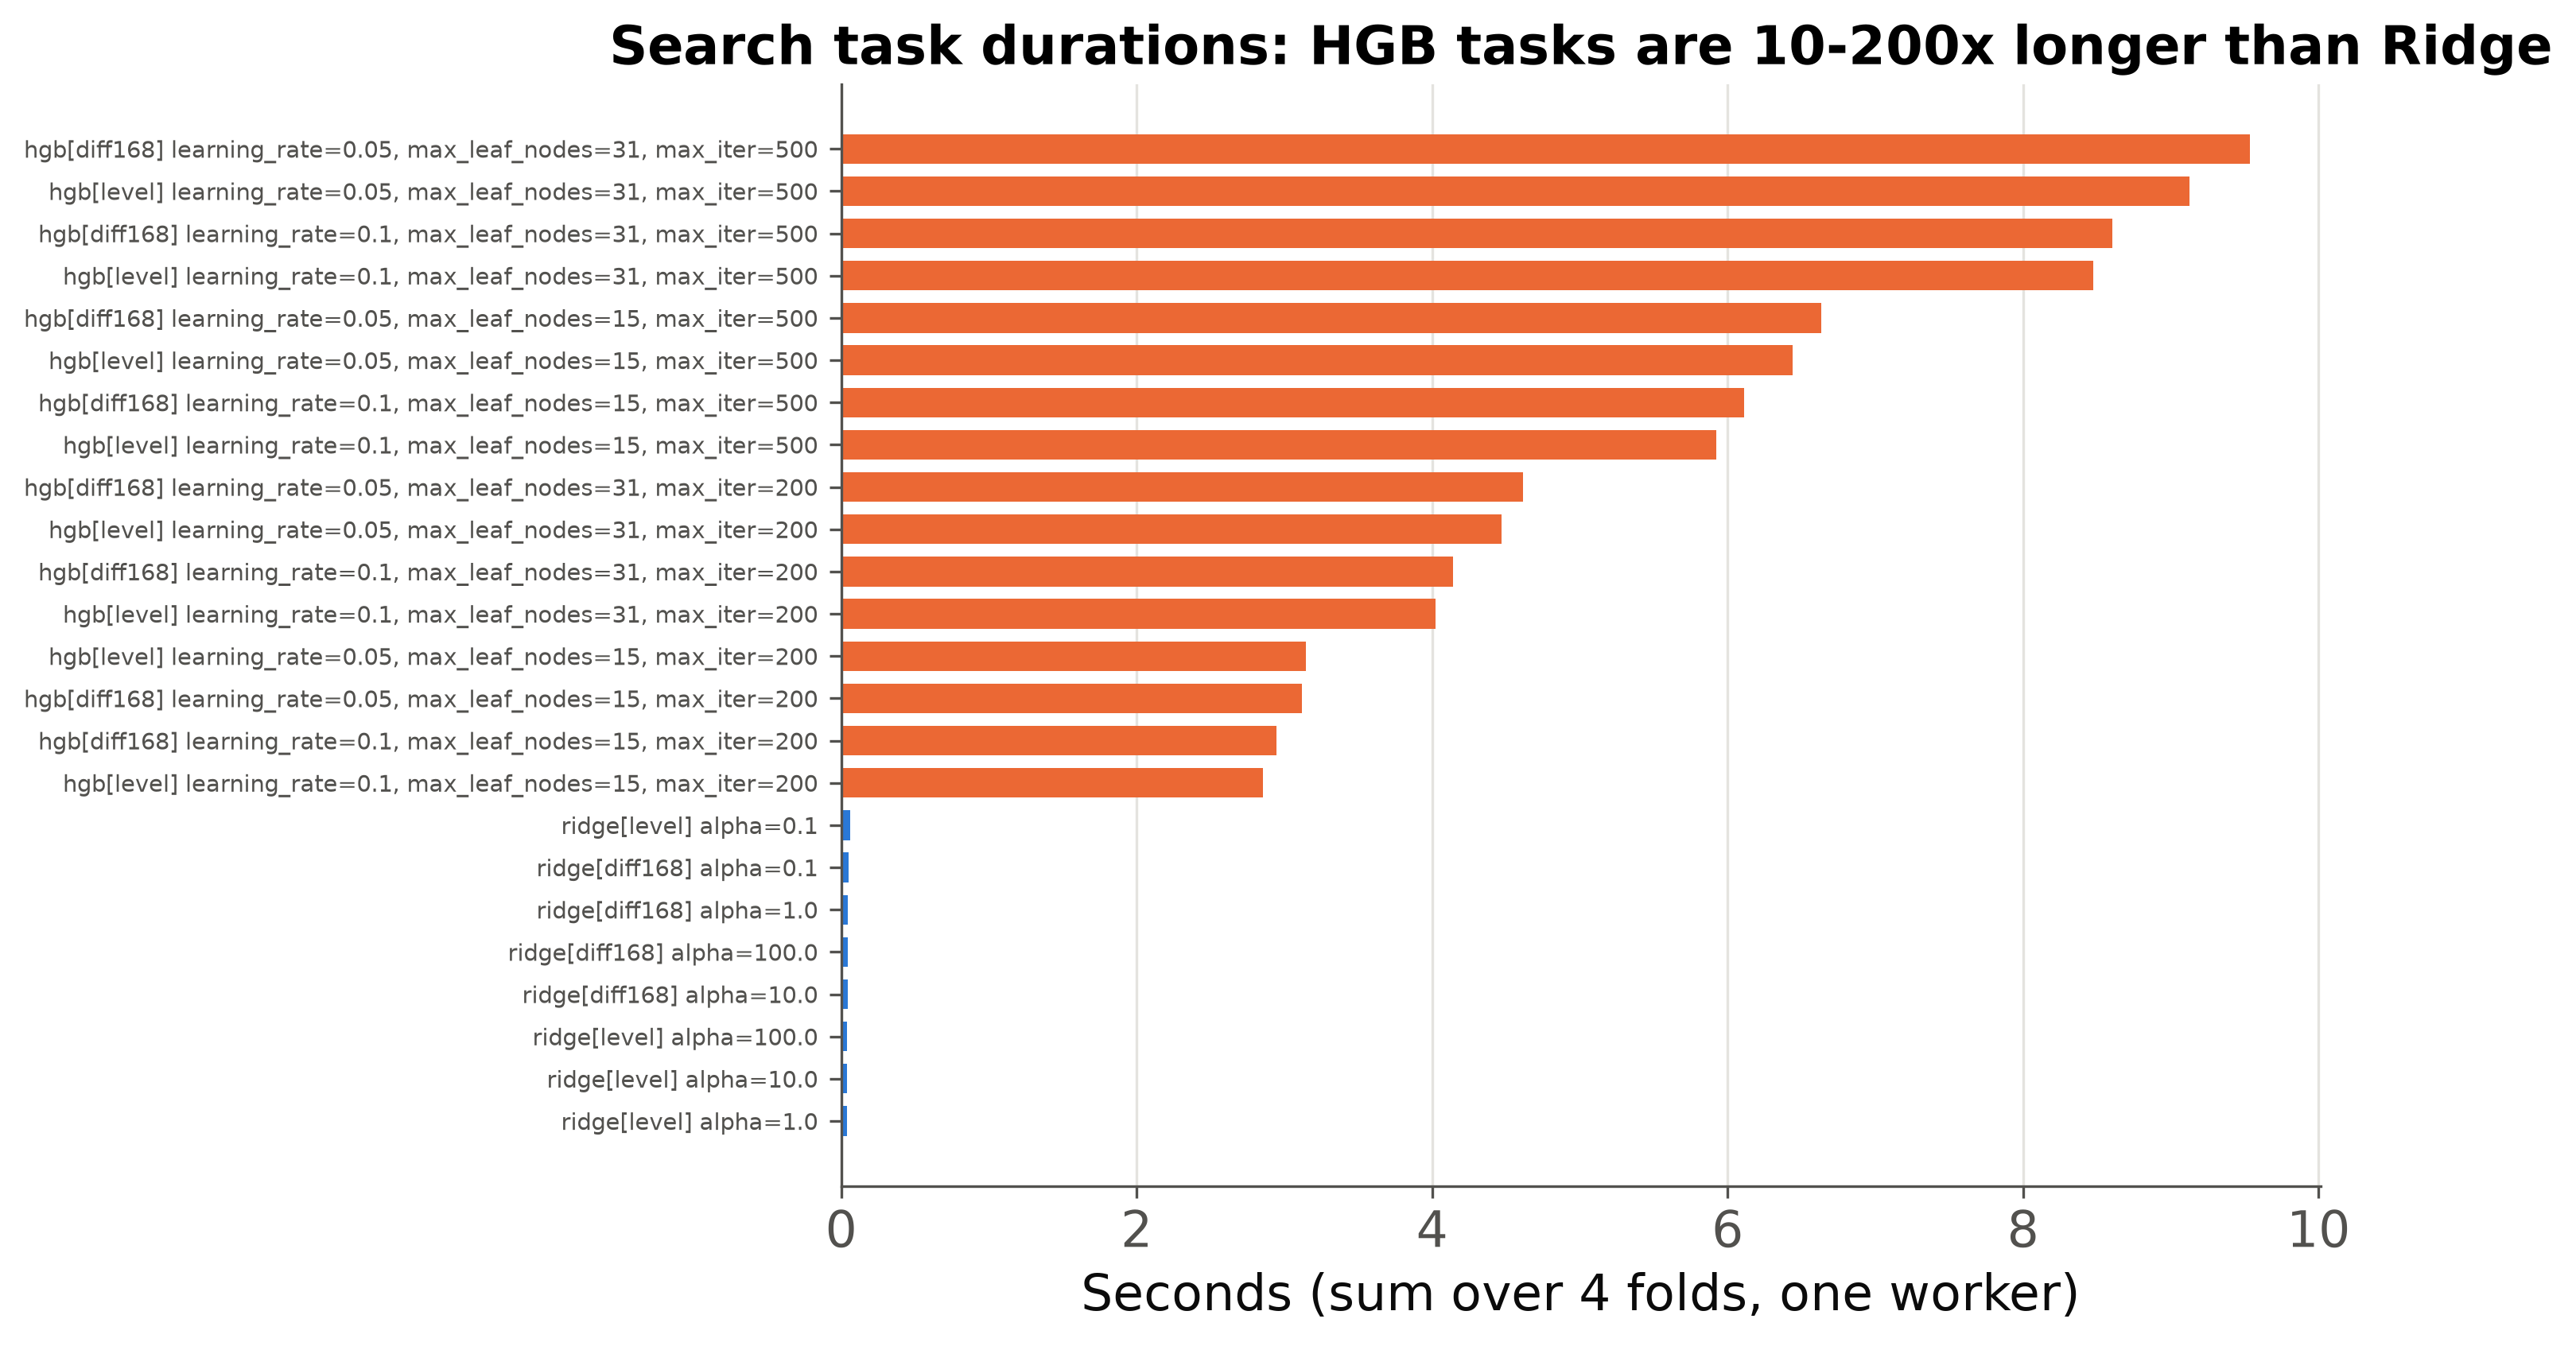

In [17]:
summary = models.summarise_search(search_seq)
summary.to_csv(config.OUTPUT_DIR / "search_summary.csv", index=False)
search_seq.to_csv(config.OUTPUT_DIR / "search_tasks.csv", index=False)
display(summary.head(8)[["label", "cv_rmse", "cv_mae", "task_seconds"]].round(2))
dur = search_seq.merge(pd.DataFrame(tasks)[["task_id", "model"]], on="task_id").groupby("model")["seconds"].agg(["mean", "max", "sum"])
display(dur.round(3))
display(Image(str(plotting.task_durations(summary))))

**Choosing the model on the validation month (August 2026).** The best setting of each model family (by mean CV
RMSE) is trained on the full training period and scored on August, next to the two baselines. The lowest
validation RMSE wins. The test month is not touched.

In [18]:
Xva, yva = parts["val"][config.FEATURE_COLUMNS], parts["val"]["y"]
candidates = summary.groupby("model").head(1)
val_rows = []
for _, c in candidates.iterrows():
    s = models.search_settings()[c["setting_id"]]
    pred = models.fit_predict(s["model"], s["params"], s["target"], Xtr, ytr, Xva)
    val_rows.append({"method": s["label"], "setting_id": s["setting_id"], **models.metrics(yva, pred)})
for lag, name in [(24, "Baseline: same hour yesterday"), (168, "Baseline: same hour last week")]:
    val_rows.append({"method": name, "setting_id": None, **models.metrics(yva, Xva[f"lag_{lag}"])})
val_table = pd.DataFrame(val_rows).sort_values("rmse").reset_index(drop=True)
val_table.to_csv(config.OUTPUT_DIR / "validation_metrics.csv", index=False)
display(val_table.round(2))
best = val_table.dropna(subset=["setting_id"]).iloc[0]
BEST = models.search_settings()[int(best["setting_id"])]
print("Chosen on validation:", BEST["label"])

RESULTS["search"] = {
    "n_tasks": len(tasks), "n_settings": len(summary), "folds": config.N_CV_FOLDS,
    "identical_to_sequential": search_equal,
    "top5": summary.head(5)[["label", "cv_rmse", "cv_mae"]].to_dict(orient="records"),
    "task_seconds_by_model": dur.round(4).to_dict(orient="index"),
    "validation": val_table.drop(columns="setting_id").to_dict(orient="records"),
    "chosen": {"label": BEST["label"], "model": BEST["model"], "params": BEST["params"], "target": BEST["target"]},
}

,method,setting_id,mae,rmse,wape_pct,mape_pct
0,"hgb[level] learning_rate=0.1, max_leaf_nodes=1...",9.0,228.50,378.07,5.39,5.98
1,ridge[diff168] alpha=100.0,15.0,332.43,485.20,7.85,10.15
2,Baseline: same hour last week,NaN,437.03,760.12,10.31,10.29
3,Baseline: same hour yesterday,NaN,805.24,1261.53,19.01,33.64


Chosen on validation: hgb[level] learning_rate=0.1, max_leaf_nodes=15, max_iter=500


# 8. Final model evaluation on the test month

The chosen setting is **retrained on train + validation** (Jan 2024 - Aug 2026) and predicts every hour of
September 2026 **one hour ahead**: each prediction uses the true pickups up to hour *t-1* (the lags are real
observations, as they would be in live use). This is the only time the test month is used.

Metrics: **MAE** (pickups/hour), **RMSE** (punishes big misses), **WAPE** = total |error| / total pickups
(the "% of actual volume" used in the course example) and MAPE.

,method,mae,rmse,wape_pct,mape_pct
0,Model: gradient boosting (predicts pickups),276.53,387.62,5.44,6.55
1,Model: Ridge regression (predicts change vs la...,415.07,561.86,8.17,11.77
2,Baseline: same hour last week,697.75,987.44,13.74,15.06
3,Baseline: same hour yesterday,908.48,1392.08,17.89,32.46


Model WAPE 5.4% vs best baseline 13.7%  -> MAE 60% lower than 'same hour last week'


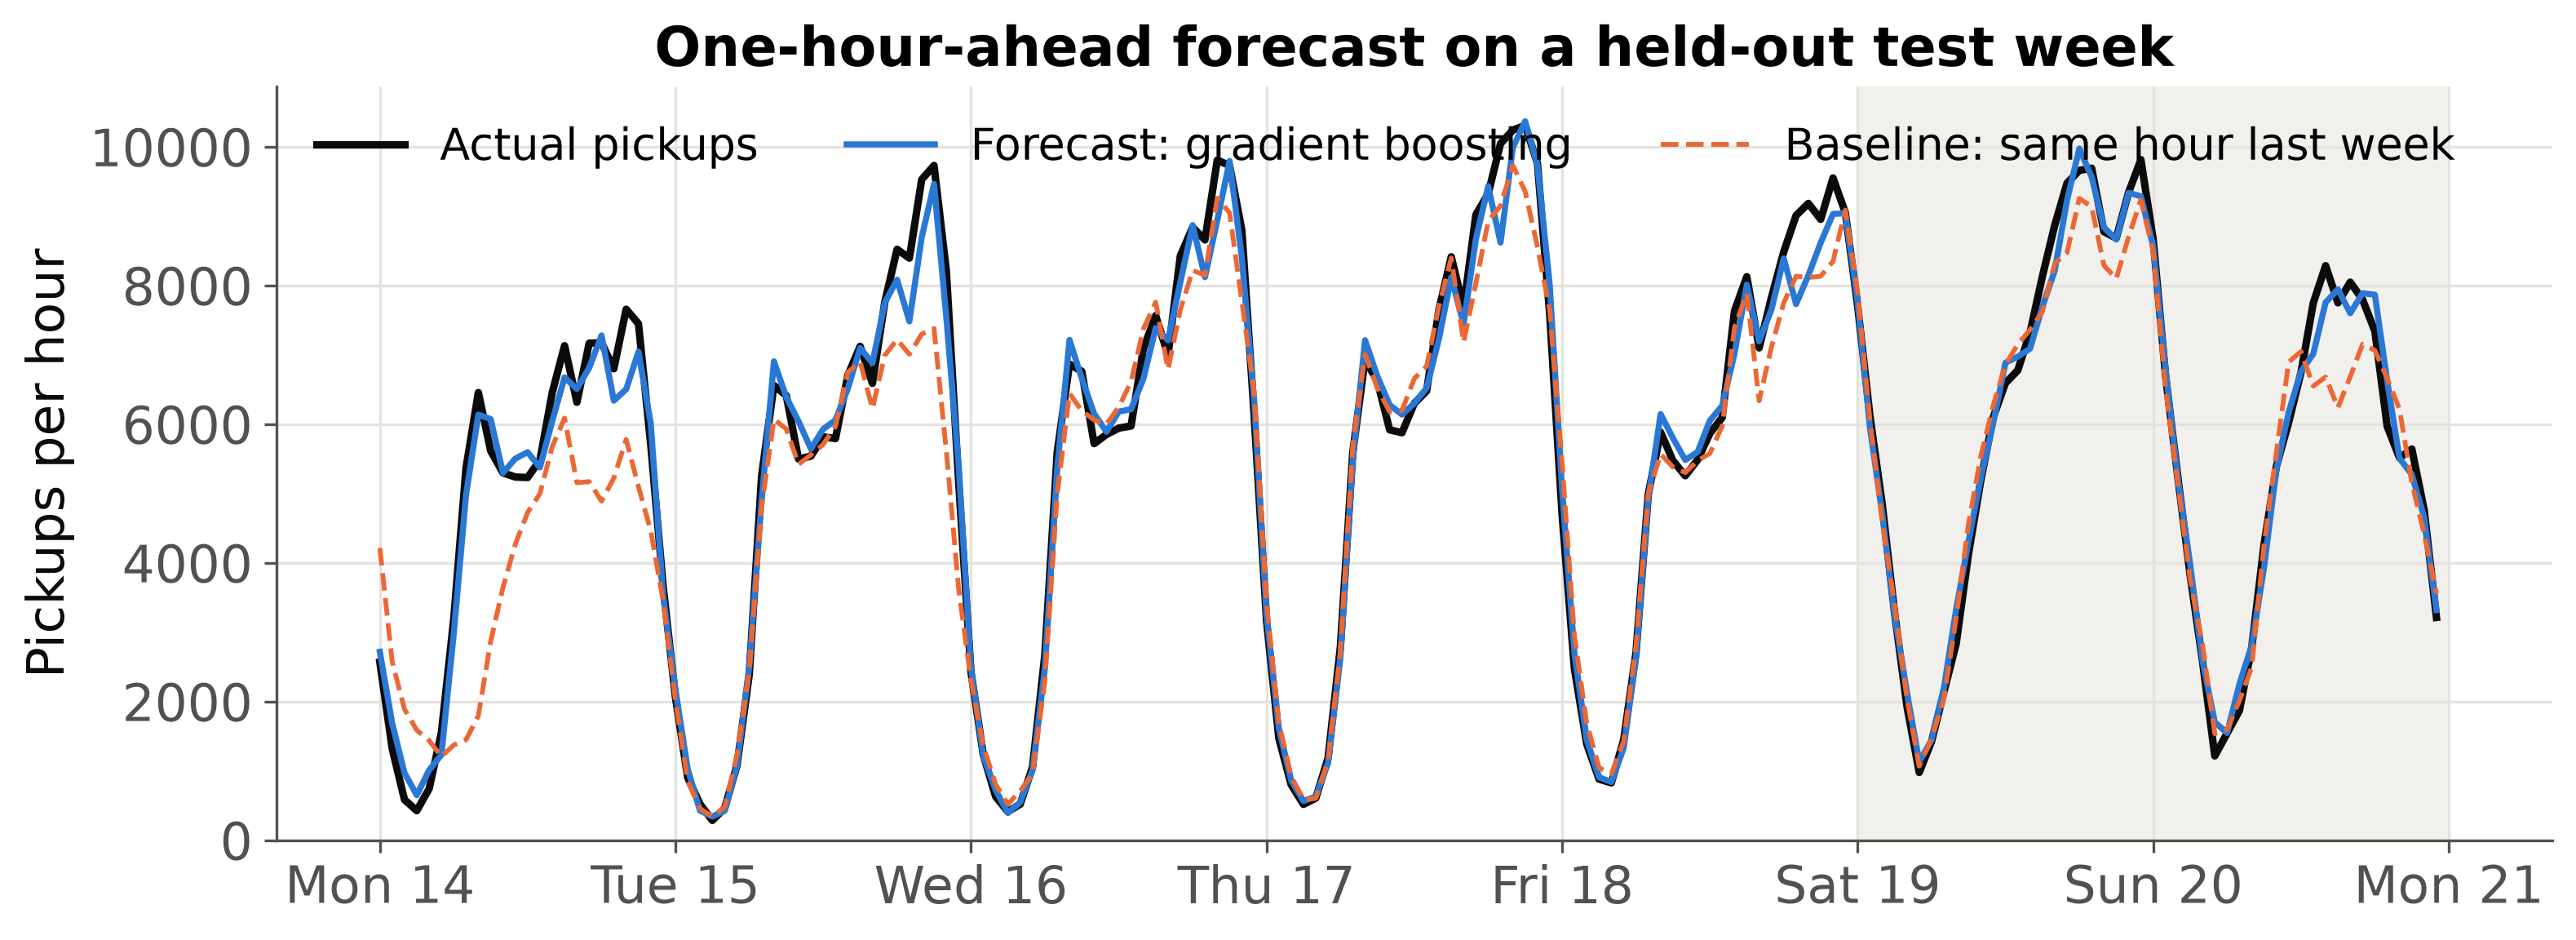

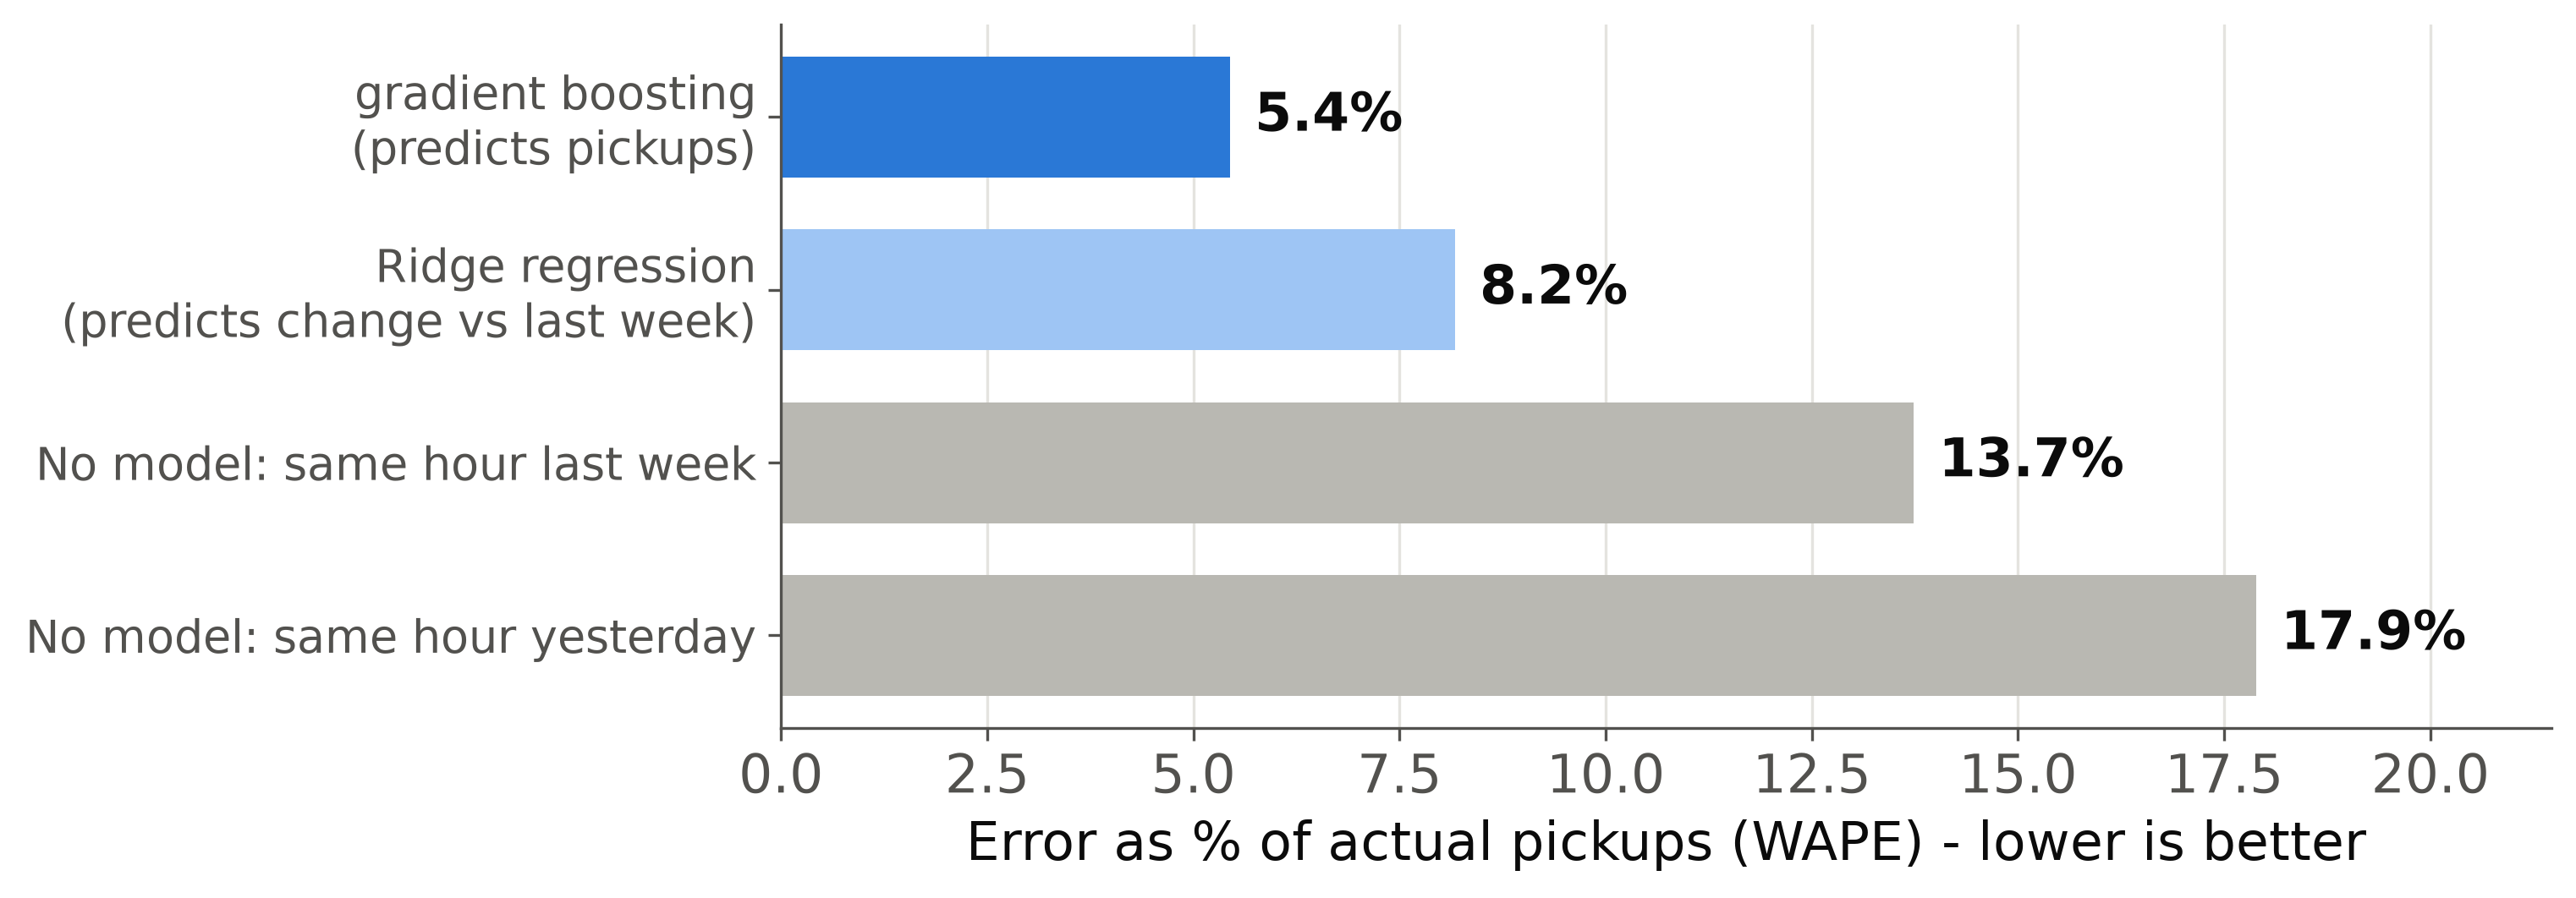

In [19]:
trval = pd.concat([parts["train"], parts["val"]])
Xte, yte = parts["test"][config.FEATURE_COLUMNS], parts["test"]["y"]
pred_test = pd.Series(models.fit_predict(BEST["model"], BEST["params"], BEST["target"],
                                         trval[config.FEATURE_COLUMNS], trval["y"], Xte), index=yte.index)
NICE = {"hgb": "gradient boosting", "ridge": "Ridge regression"}
TARGET = {"level": "predicts pickups", "diff168": "predicts change vs last week"}
rows = [{"method": f"Model: {NICE[BEST['model']]} ({TARGET[BEST['target']]})", **models.metrics(yte, pred_test)}]
# The runner-up family, for context (also retrained on train + val)
other = val_table.dropna(subset=["setting_id"]).iloc[1]
OTHER = models.search_settings()[int(other["setting_id"])]
pred_other = models.fit_predict(OTHER["model"], OTHER["params"], OTHER["target"], trval[config.FEATURE_COLUMNS], trval["y"], Xte)
rows.append({"method": f"Model: {NICE[OTHER['model']]} ({TARGET[OTHER['target']]})", **models.metrics(yte, pred_other)})
rows.append({"method": "Baseline: same hour last week", **models.metrics(yte, Xte["lag_168"])})
rows.append({"method": "Baseline: same hour yesterday", **models.metrics(yte, Xte["lag_24"])})
test_metrics = pd.DataFrame(rows)
test_metrics.to_csv(config.OUTPUT_DIR / "metrics.csv", index=False)
display(test_metrics.round(2))
pd.DataFrame({"actual": yte, "model": pred_test, "same_hour_last_week": Xte["lag_168"],
              "same_hour_yesterday": Xte["lag_24"]}).to_csv(config.OUTPUT_DIR / "test_predictions.csv")

m_model = test_metrics.iloc[0]
m_base = test_metrics[test_metrics["method"] == "Baseline: same hour last week"].iloc[0]
improvement = 100 * (1 - m_model["mae"] / m_base["mae"])
print(f"Model WAPE {m_model['wape_pct']:.1f}% vs best baseline {m_base['wape_pct']:.1f}%  "
      f"-> MAE {improvement:.0f}% lower than 'same hour last week'")

# A full Monday-Sunday week inside the test month for the figure
week_start = str(yte.index[yte.index.day_of_week == 0][24].normalize().date())
display(Image(str(plotting.forecast_vs_actual(yte, pred_test, Xte["lag_168"], NICE[BEST["model"]],
                                              "same hour last week", week_start))))
display(Image(str(plotting.error_vs_baseline(test_metrics))))

RESULTS["test"] = {"metrics": test_metrics.to_dict(orient="records"), "chosen": BEST["label"],
                   "mae_improvement_vs_last_week_pct": float(improvement), "figure_week_start": week_start,
                   "mean_actual_pickups_per_hour": float(yte.mean())}

# 9. Sequential vs parallel benchmarks and Amdahl's law

The full benchmark runs in a separate Slurm job (`scripts/benchmark.py`, `run_benchmark.slurm`) because it
repeats every workload many times. For each workload it runs: the true sequential loop; a 1-worker pool (to
expose pool overhead); 2, 4 and 8 workers. Each configuration gets **one discarded warm-up run** (it fills the
file cache and imports libraries in the workers) and then **3 timed runs** (`time.perf_counter`); we report the
mean and standard deviation. **Every timed run's output is asserted equal to the sequential output.**

- speedup S_k = T_sequential / T_k,   efficiency E_k = S_k / k
- Amdahl: S_k = 1 / ((1 - p) + p / k), so the parallel fraction is p = (1 - 1/S_k) / (1 - 1/k) and the best
  possible speedup with unlimited workers is 1 / (1 - p).

{'hostname': 'rockhill', 'cpu_model': 'AMD EPYC 9124 16-Core Processor', 'cpus_slurm_allocated': 8, 'slurm_job_id': '2011', 'start': '2026-11-23 16:12:33', 'end': '2026-11-23 16:59:43', 'load_average_start': [124.25732421875, 124.04931640625, 123.9296875], 'repeats': 3}
Pool start-up cost (s) by workers: {'1': 0.036, '2': 0.05, '4': 0.067, '8': 0.103}


,workload,mode,workers,mean_s,std_s,repeats,speedup,efficiency,amdahl_p,max_speedup
0,cleaning,parallel,1,132.470,0.429,3,0.950,0.950,NaN,NaN
1,cleaning,parallel,2,69.288,2.106,3,1.816,0.908,0.898,9.841
2,cleaning,parallel,4,37.521,0.617,3,3.353,0.838,0.936,15.535
3,cleaning,parallel,8,21.829,0.294,3,5.763,0.720,0.945,18.031
4,cleaning,sequential,1,125.794,0.030,3,1.000,1.000,NaN,NaN
5,features,parallel,1,0.110,0.005,3,0.163,0.163,NaN,NaN
6,features,parallel,2,0.133,0.005,3,0.135,0.067,-12.838,NaN
7,features,parallel,4,0.189,0.012,3,0.095,0.024,-12.724,NaN
8,features,parallel,8,0.303,0.005,3,0.059,0.007,-18.155,NaN
9,features,sequential,1,0.018,0.002,3,1.000,1.000,NaN,NaN


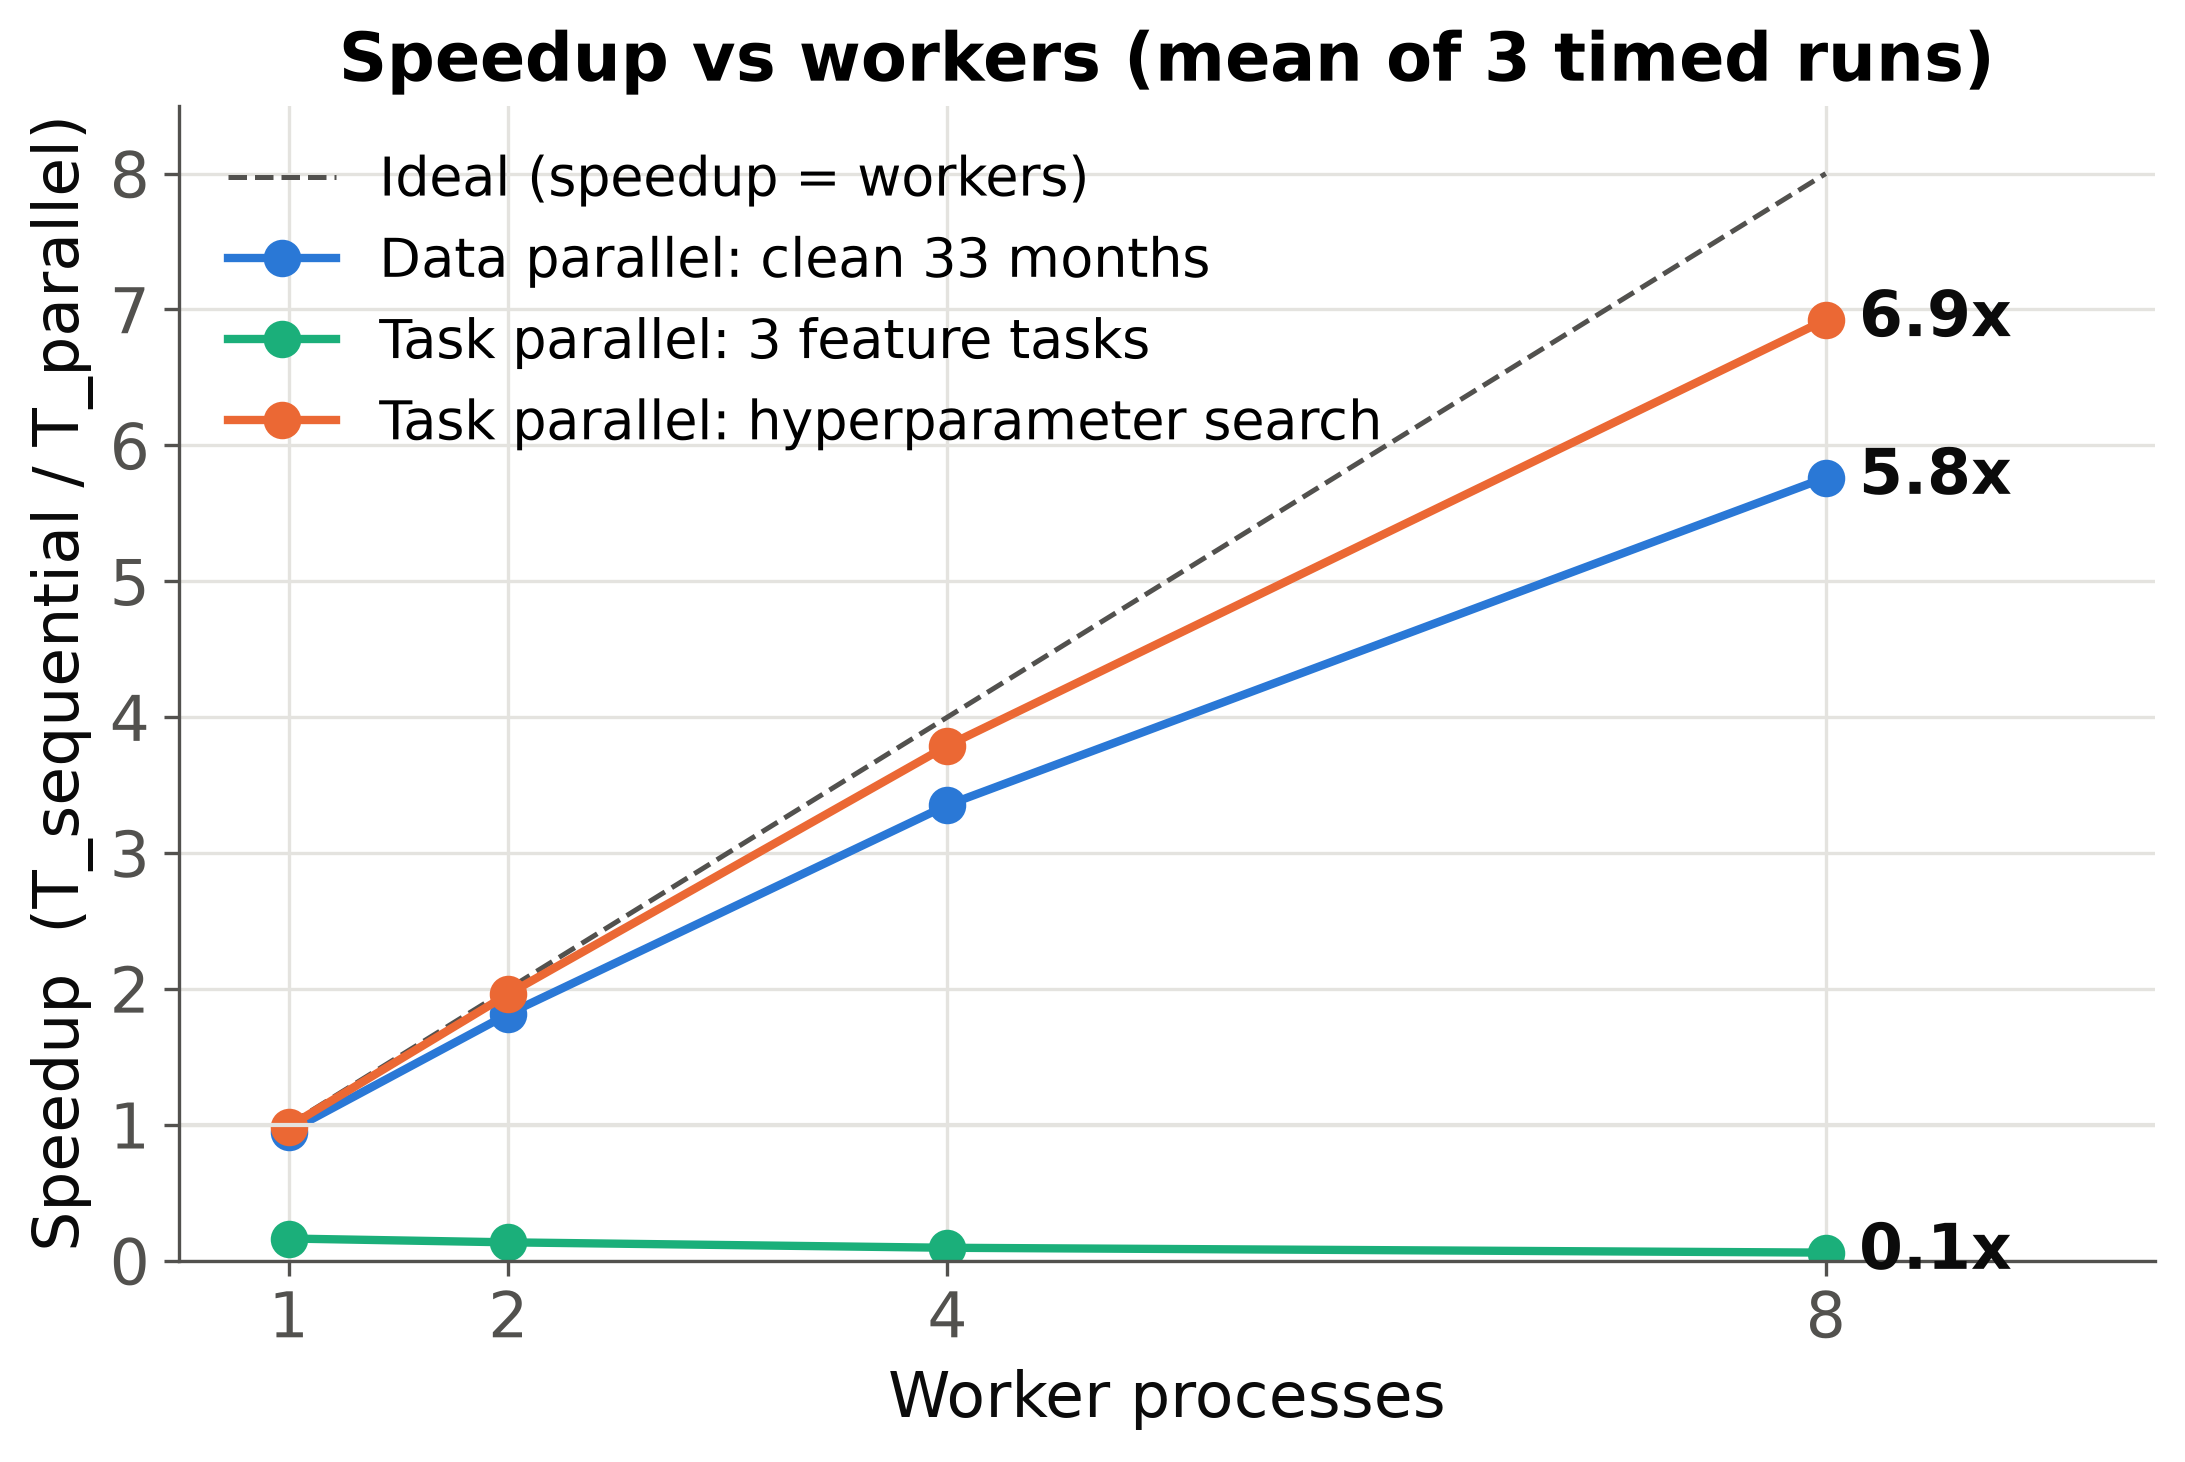

In [20]:
bench = pd.read_csv(config.OUTPUT_DIR / "benchmarks.csv")
bench_meta = json.loads((config.OUTPUT_DIR / "benchmark_meta.json").read_text())
bsum = parallel.speedup_table(bench)
bsum.to_csv(config.OUTPUT_DIR / "benchmark_summary.csv", index=False)
# CPUs Slurm allocated to the benchmark job (from the job's environment, or its sbatch script).
# Rockhill's Slurm does not pin cores, so the CPUs a job can *see* (64) are more than it was allocated.
import re
bench_cpus = bench_meta.get("slurm_cpus_per_task") or re.search(
    r"--cpus-per-task=(\d+)", Path("run_benchmark.slurm").read_text()).group(1)
bench_meta["cpus_slurm_allocated"] = int(bench_cpus)
print({k: bench_meta[k] for k in ["hostname", "cpu_model", "cpus_slurm_allocated", "slurm_job_id", "start", "end",
                                   "load_average_start", "repeats"]})
print("Pool start-up cost (s) by workers:", {k: round(v, 3) for k, v in bench_meta["pool_startup_s"].items()})
display(bsum.round(3))
display(Image(str(plotting.speedup(bsum))))

In [21]:
k_max = int(bsum["workers"].max())
amdahl = (bsum[(bsum["mode"] == "parallel") & (bsum["workers"] == k_max)]
          .set_index("workload")[["mean_s", "speedup", "efficiency", "amdahl_p", "max_speedup"]])
display(amdahl.round(3))
RESULTS["benchmarks"] = {
    "meta": {k: bench_meta[k] for k in ["hostname", "cpu_model", "cpus_slurm_allocated", "repeats", "worker_counts",
                                         "load_average_start", "load_average_end", "pool_startup_s", "start"]},
    "summary": bsum.round(4).to_dict(orient="records"),
    "at_max_workers": amdahl.round(4).to_dict(orient="index"), "max_workers": k_max,
}

,mean_s,speedup,efficiency,amdahl_p,max_speedup
workload,,,,,
cleaning,21.829,5.763,0.720,0.945,18.031
features,0.303,0.059,0.007,-18.155,NaN
search,13.058,6.924,0.865,0.978,45.023


**Why is the speedup below ideal?** (numbers above)
- **Serial parts (Amdahl):** creating the pool, the final concat/sort, and the main process waiting.
- **Process start-up and transfer:** each worker is a new process; results (and for the search, the training
  data) are pickled between processes. For the feature tasks this overhead is larger than the work itself.
- **Disk I/O contention:** in the cleaning workload all workers read Parquet files from the same disk at once.
- **Load imbalance:** 33 month shards on 8 workers leave a last round with one busy worker; in the search a few
  500-iteration boosting tasks dominate the end of the run.
- **Shared server:** Rockhill is used by the whole class and by long-running research jobs. The load average at
  benchmark time is recorded above; other users' processes compete for the same cores and memory bandwidth.

# 10. Non-determinism: evidence and fixes

Same code, same data, different answer on each run - three sources, each shown **broken** (outputs differ)
and then **fixed twice** (outputs identical).

**Sources 1 and 2 - completion order and floating-point reduction order** (the real cleaning rules on all 33
months). The broken version collects results with `submit` + `as_completed` and combines them *in the order they
finish*: the rows of the hourly series come out in a different order (different hash, different first hour).
It also adds up the **sum of squared fares** (needed for the standard deviation of all 115 M fares) from 24,096
hourly partial sums in that order, and the last digits change because float addition is not associative.
A random 0-2 s sleep in each worker makes the order change visible every run; on a busy shared server finishing
order varies anyway.

*Why squared fares and three broken runs?* We measured it: with 33 monthly fare subtotals, a different order
changed the total in only some runs (fares are whole cents, so many orders round identically). With 24,096 hourly
sums of squares the chance that two random orders give the same total is about 1%, so with three broken runs an
accidental tie is practically impossible. Either way the lesson holds: the result *can* change between runs.

In [22]:
a = nondeterminism.tiny_float_example()
print("Float addition is not associative:", a)
ND = []
for run in (1, 2, 3):
    r = nondeterminism.combine_broken(FILES, N_WORKERS)
    ND.append({"source": "completion+reduction order", "version": "broken", "run": run, **{k: r[k] for k in ["series_hash", "first_hour", "fare_sq_hex"]}, "fare_sq_total": repr(r["fare_sq_total"]), "order_head": ",".join(r["order"][:4])})
for run in (1, 2):
    r = nondeterminism.combine_fixed(FILES, N_WORKERS)
    ND.append({"source": "completion+reduction order", "version": "fixed", "run": run, **{k: r[k] for k in ["series_hash", "first_hour", "fare_sq_hex"]}, "fare_sq_total": repr(r["fare_sq_total"]), "order_head": ",".join(r["order"][:4]), "fare_sq_fsum_hex": r["fare_sq_fsum_hex"]})
nd1 = pd.DataFrame(ND)
display(nd1[["version", "run", "order_head", "first_hour", "series_hash", "fare_sq_total", "fare_sq_hex"]])
broken1, fixed1 = nd1[nd1.version == "broken"], nd1[nd1.version == "fixed"]
print("broken runs: all same series?", broken1.series_hash.nunique() == 1, "  all same sum of squares?", broken1.fare_sq_hex.nunique() == 1)
print("fixed runs:  same series?", fixed1.series_hash.nunique() == 1, "  same sum of squares?", fixed1.fare_sq_hex.nunique() == 1,
      "  fixed series equals pipeline output?", fixed1.series_hash.iloc[0] == nondeterminism.series_hash(y))

Float addition is not associative: {'(a+b)+c': 1.0, 'a+(b+c)': 0.0}


,version,run,order_head,first_hour,series_hash,fare_sq_total,fare_sq_hex
0,broken,1,"2024-07,2024-08,2024-02,2024-06",2024-07-01 00:00:00,f44027a1b343,1168997580231.7642,0x1.102daf7dc7c3ap+40
1,broken,2,"2024-07,2024-08,2024-01,2024-02",2024-07-01 00:00:00,b646548b967e,1168997580231.7737,0x1.102daf7dc7c61p+40
2,broken,3,"2024-08,2024-07,2024-01,2024-02",2024-08-01 00:00:00,9c7701d57691,1168997580231.7651,0x1.102daf7dc7c3ep+40
3,fixed,1,"2024-01,2024-02,2024-03,2024-04",2024-01-01 00:00:00,19657da16f9c,1168997580231.7747,0x1.102daf7dc7c65p+40
4,fixed,2,"2024-01,2024-02,2024-03,2024-04",2024-01-01 00:00:00,19657da16f9c,1168997580231.7747,0x1.102daf7dc7c65p+40


broken runs: all same series? False   all same sum of squares? False
fixed runs:  same series? True   same sum of squares? True   fixed series equals pipeline output? True


**Fix for sources 1 and 2:** sort the results by shard id (month) before combining, and add the partial sums in
that fixed order (`math.fsum`, which is exactly rounded and therefore independent of order, is an alternative).
In the main pipeline `executor.map` already returns results in input order, and `combine_months` sorts by month.
**Limits:** sorting forces us to wait for *all* shards before combining (no streaming reduction) and costs a
sort; a fixed order makes the float sum *repeatable*, not *more accurate*; `fsum` is exact but slower and only
works for plain sums.

**Source 3 - unseeded randomness.** A random hyperparameter search draws settings from an unseeded generator,
and gradient boosting with early stopping holds out a random validation subset. Two runs pick different "best"
settings with different scores. **Fix:** one base seed for the search generator, and a per-trial seed
`SEED + trial_id` passed into each model (in a parallel search each worker gets its task's seed, so the result does
not depend on which worker ran it). **Limits:** results are reproducible only for the same task list, library
versions and data; a seed fixes *one* sample of the randomness, it does not tell you how much results vary
(for that, run several seeds deliberately).

In [23]:
for run in (1, 2):
    ND.append({"source": "unseeded randomness", "version": "broken", "run": run, **nondeterminism.random_search_broken(Xtr, ytr)})
for run in (1, 2):
    ND.append({"source": "unseeded randomness", "version": "fixed", "run": run, **nondeterminism.random_search_fixed(Xtr, ytr)})
nd3 = pd.DataFrame(ND[5:])[["version", "run", "learning_rate", "max_leaf_nodes", "rmse"]]
display(nd3)
b3, f3 = nd3[nd3.version == "broken"], nd3[nd3.version == "fixed"]
print("broken runs identical?", bool(b3.drop(columns="run").drop(columns="version").duplicated().iloc[-1]))
print("fixed runs identical?", bool(f3.drop(columns="run").drop(columns="version").duplicated().iloc[-1]))

,version,run,learning_rate,max_leaf_nodes,rmse
0,broken,1,0.074631,59,442.769872
1,broken,2,0.097170,17,440.678218
2,fixed,1,0.080645,19,440.880863
3,fixed,2,0.080645,19,440.880863


broken runs identical? False
fixed runs identical? True


**Source 4 (prevented, not demonstrated): thread-count-dependent maths.** Multi-threaded BLAS/OpenMP can split a
sum differently depending on the number of threads, which changes the last digits. We pin
`OMP_NUM_THREADS = OPENBLAS_NUM_THREADS = MKL_NUM_THREADS = 1` in every process (top of this notebook and the
pool initializer), which also stops 8 workers from each starting dozens of threads.

In [24]:
nd_all = pd.DataFrame(ND)
nd_all.to_csv(config.OUTPUT_DIR / "nondeterminism.csv", index=False)
def differs(df, cols):
    return bool(df[cols].drop_duplicates().shape[0] > 1)
RESULTS["nondeterminism"] = {
    "tiny_example": a,
    "completion_order": {"broken_runs_differ": differs(broken1, ["series_hash"]), "fixed_runs_identical": not differs(fixed1, ["series_hash"]),
                         "fixed_equals_pipeline": bool(fixed1.series_hash.iloc[0] == nondeterminism.series_hash(y))},
    "reduction_order": {"broken_runs_differ": differs(broken1, ["fare_sq_hex"]), "fixed_runs_identical": not differs(fixed1, ["fare_sq_hex"]),
                        "fixed_fare_sq_total": float.fromhex(fixed1.fare_sq_hex.iloc[0])},
    "unseeded_randomness": {"broken_runs_differ": differs(b3, ["learning_rate", "max_leaf_nodes", "rmse"]),
                            "fixed_runs_identical": not differs(f3, ["learning_rate", "max_leaf_nodes", "rmse"])},
    # The broken runs are random by design, so their values change on every notebook run.
    "broken_evidence_this_run": {
        "series_hash": list(broken1.series_hash), "first_hour": list(broken1.first_hour),
        "fare_sq_total": list(broken1.fare_sq_total), "random_search_best": b3[["learning_rate", "max_leaf_nodes", "rmse"]].round(4).to_dict(orient="records"),
    },
    "fixed_evidence": {"series_hash": fixed1.series_hash.iloc[0], "fare_sq_total": fixed1.fare_sq_total.iloc[0],
                       "random_search_best": f3.iloc[0][["learning_rate", "max_leaf_nodes", "rmse"]].to_dict()},
}
print(json.dumps({k: v for k, v in RESULTS["nondeterminism"].items() if k != "broken_evidence_this_run"}, indent=1, default=str))

{
 "tiny_example": {
  "(a+b)+c": 1.0,
  "a+(b+c)": 0.0
 },
 "completion_order": {
  "broken_runs_differ": true,
  "fixed_runs_identical": true,
  "fixed_equals_pipeline": true
 },
 "reduction_order": {
  "broken_runs_differ": true,
  "fixed_runs_identical": true,
  "fixed_fare_sq_total": 1168997580231.7747
 },
 "unseeded_randomness": {
  "broken_runs_differ": true,
  "fixed_runs_identical": true
 },
 "fixed_evidence": {
  "series_hash": "19657da16f9c",
  "fare_sq_total": "1168997580231.7747",
  "random_search_best": {
   "learning_rate": 0.08064518411923295,
   "max_leaf_nodes": 19,
   "rmse": 440.8808634119707
  }
 }
}


# 11. Results summary

Everything the poster and the presentation quote is written to **`outputs/results.json`** - the single source
of truth. The poster is generated from this file by `scripts/make_poster.py`; no number is typed by hand.

In [25]:
RESULTS["timing_this_run"] = {
    "clean_sequential_s": t_clean_seq, "clean_parallel_s": t_clean_par, "clean_workers": N_WORKERS,
    "search_sequential_s": t_search_seq, "search_parallel_s": t_search_par,
    "features_sequential_ms": float(np.mean(feat_seq_times) * 1000), "features_parallel_ms": float(np.mean(feat_par_times) * 1000),
    "notebook_seconds": time.perf_counter() - NOTEBOOK_START,
}
(config.OUTPUT_DIR / "results.json").write_text(json.dumps(RESULTS, indent=1, default=str))
c, t = RESULTS["cleaning"], RESULTS["test"]
print(f"Trips: {c['raw_rows']:,} raw -> {c['kept_rows']:,} kept ({c['kept_pct']:.1f}%), {c['hourly_observations']:,} hourly observations")
print(f"Test month: model WAPE {m_model['wape_pct']:.1f}% vs same-hour-last-week {m_base['wape_pct']:.1f}%")
for wl, r in RESULTS["benchmarks"]["at_max_workers"].items():
    print(f"{wl:9s}: speedup {r['speedup']:.2f}x on {k_max} workers, efficiency {r['efficiency']:.2f}, Amdahl p = {r['amdahl_p']:.2f}")
print("All parallel results identical to sequential:", clean_equal and feat_equal and search_equal)

Trips: 123,471,721 raw -> 115,358,059 kept (93.4%), 24,096 hourly observations
Test month: model WAPE 5.4% vs same-hour-last-week 13.7%
cleaning : speedup 5.76x on 8 workers, efficiency 0.72, Amdahl p = 0.94
features : speedup 0.06x on 8 workers, efficiency 0.01, Amdahl p = -18.15
search   : speedup 6.92x on 8 workers, efficiency 0.87, Amdahl p = 0.98
All parallel results identical to sequential: True


# 12. Reproducibility notes

- **Re-run:** `sbatch run_benchmark.slurm` (optional, ~1 h, refreshes `outputs/benchmarks.csv`), then
  `sbatch run_notebook.slurm`. Python environment: `pip install -r requirements.txt` in a venv.
- **Data:** `/home/cs4207/data/yellow_tripdata_2024-01.parquet` ... `2026-09.parquet` (NYC TLC), read in place.
- **Deterministic by design:** fixed seeds (`config.SEED`), single-threaded maths, ordered `map`, results
  sorted by shard / task id. Only timings and the deliberately broken demos in section 10 change between runs;
  `scripts/compare_results.py` checks that two runs' `results.json` agree on everything else.
- **Hardware and run time** are printed below.

In [26]:
total = time.perf_counter() - NOTEBOOK_START
print(f"Notebook run time: {total / 60:.1f} min on {env['cpus_allocated']} CPUs ({env['cpu_model']}), host {env['hostname']}, GPU: none")
print("Library versions:", {k: env[k] for k in ["python", "pandas", "numpy", "pyarrow", "scikit-learn", "matplotlib"]})

Notebook run time: 7.1 min on 8 CPUs (AMD EPYC 9124 16-Core Processor), host rockhill, GPU: none
Library versions: {'python': '3.12.3', 'pandas': '3.1.1', 'numpy': '2.5.5', 'pyarrow': '26.0.1', 'scikit-learn': '1.9.1', 'matplotlib': '3.11.2'}
